In [5]:
import numpy as np
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import os

# TensorBoard日志路径
tb_sopo = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251219_ragtruth_10k_fb_rand_prompt_next_nr24_norm_after_scaling"
tb_ori = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251211_ragtruth_10k_ori"
# tb_ori = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251228_ragtruth_10k_ori_ds"
tb_rl4hs = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251211_ragtruth_10k_capo_ori"
tb_sopo_n8 = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251222_ragtruth_10k_fb_rand_prompt_next_nr24_norm_after_scaling_n8"
tb_sopo_corrupt = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251215_ragtruth_10k_fb_light"

tb_analysis_only = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251229_ragtruth_10k_fb_rand_prompt_next_nr8_norm_after_scaling_analysis_only"
tb_guidance_only = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251230_ragtruth_10k_fb_rand_prompt_next_nr8_norm_after_scaling_guidance_only"
tb_spoiler = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251231_ragtruth_10k_fb_rand_prompt_next_nr8_norm_after_scaling_spoiler"

def load_tensorboard_scalar(event_dir, scalar_name):
    """从TensorBoard日志中加载标量数据"""
    if not os.path.exists(event_dir):
        print(f"Warning: {event_dir} does not exist")
        return None, None
    
    ea = EventAccumulator(event_dir)
    ea.Reload()
    
    if scalar_name not in ea.Tags()['scalars']:
        print(f"Warning: {scalar_name} not found in {event_dir}")
        return None, None
    
    scalar_events = ea.Scalars(scalar_name)
    steps = [s.step for s in scalar_events]
    values = [s.value for s in scalar_events]
    
    return np.array(steps), np.array(values)

def smooth(scalars, weight=0.97):
    """Exponential moving average smoothing (TensorBoard style)"""
    last = scalars[0]
    smoothed = []
    for point in scalars:
        smoothed_val = last * weight + (1 - weight) * point
        smoothed.append(smoothed_val)
        last = smoothed_val
    return np.array(smoothed)

In [ ]:


# 加载数据
metric_name = "ppo_actor/task_reward/avg"
metric_entropy_name = "ppo_actor/update/entropy/avg"
metric_grad_norm_name = "ppo_actor/update/grad_norm"

steps_sopo, values_sopo = load_tensorboard_scalar(tb_sopo, metric_name)
steps_ori, values_ori = load_tensorboard_scalar(tb_ori, metric_name)
steps_rl4hs, values_rl4hs = load_tensorboard_scalar(tb_rl4hs, metric_name)
steps_sopo_t1, values_sopo_t1 = load_tensorboard_scalar(tb_sopo, "ppo_actor/f1_first_turn/avg")
steps_sopo_corrupt, values_sopo_corrupt = load_tensorboard_scalar(tb_sopo_corrupt, metric_name)

# 加载entropy数据
steps_sopo_entropy, values_sopo_entropy = load_tensorboard_scalar(tb_sopo, metric_entropy_name)
steps_ori_entropy, values_ori_entropy = load_tensorboard_scalar(tb_ori, metric_entropy_name)
steps_rl4hs_entropy, values_rl4hs_entropy = load_tensorboard_scalar(tb_rl4hs, metric_entropy_name)

# 加载grad_norm数据
steps_sopo_grad, values_sopo_grad = load_tensorboard_scalar(tb_sopo, metric_grad_norm_name)
steps_ori_grad, values_ori_grad = load_tensorboard_scalar(tb_ori, metric_grad_norm_name)
steps_rl4hs_grad, values_rl4hs_grad = load_tensorboard_scalar(tb_rl4hs, metric_grad_norm_name)

print(f"SOPO: {len(steps_sopo) if steps_sopo is not None else 0} data points")
print(f"ORI: {len(steps_ori) if steps_ori is not None else 0} data points")
print(f"RL4HS: {len(steps_rl4hs) if steps_rl4hs is not None else 0} data points")
print(f"Entropy - SOPO: {len(steps_sopo_entropy) if steps_sopo_entropy is not None else 0}, ORI: {len(steps_ori_entropy) if steps_ori_entropy is not None else 0}, RL4HS: {len(steps_rl4hs_entropy) if steps_rl4hs_entropy is not None else 0}")
print(f"Grad Norm - SOPO: {len(steps_sopo_grad) if steps_sopo_grad is not None else 0}, ORI: {len(steps_ori_grad) if steps_ori_grad is not None else 0}, RL4HS: {len(steps_rl4hs_grad) if steps_rl4hs_grad is not None else 0}")

# 加载seq_len和turns数据
metric_seq_len_name = "ppo_actor/seq_len/avg"
metric_turns_name = "rollout/turns"

# 加载seq_len数据
steps_sopo_n8_seq_len, values_sopo_n8_seq_len = load_tensorboard_scalar(tb_sopo_n8, metric_seq_len_name)
steps_ori_seq_len, values_ori_seq_len = load_tensorboard_scalar(tb_ori, metric_seq_len_name)
steps_rl4hs_seq_len, values_rl4hs_seq_len = load_tensorboard_scalar(tb_rl4hs, metric_seq_len_name)

# 加载turns数据
steps_sopo_n8_turns, values_sopo_n8_turns = load_tensorboard_scalar(tb_sopo_n8, metric_turns_name)
steps_ori_turns, values_ori_turns = load_tensorboard_scalar(tb_ori, metric_turns_name)
steps_rl4hs_turns, values_rl4hs_turns = load_tensorboard_scalar(tb_rl4hs, metric_turns_name)

print(f"Seq Len - SOPO_N8: {len(steps_sopo_n8_seq_len) if steps_sopo_n8_seq_len is not None else 0}, ORI: {len(steps_ori_seq_len) if steps_ori_seq_len is not None else 0}, RL4HS: {len(steps_rl4hs_seq_len) if steps_rl4hs_seq_len is not None else 0}")
print(f"Turns - SOPO_N8: {len(steps_sopo_n8_turns) if steps_sopo_n8_turns is not None else 0}, ORI: {len(steps_ori_turns) if steps_ori_turns is not None else 0}, RL4HS: {len(steps_rl4hs_turns) if steps_rl4hs_turns is not None else 0}")

SOPO: 948 data points
ORI: 632 data points
RL4HS: 632 data points
Entropy - SOPO: 948, ORI: 632, RL4HS: 632
Grad Norm - SOPO: 948, ORI: 632, RL4HS: 632
Seq Len - SOPO_N8: 694, ORI: 632, RL4HS: 632
Turns - SOPO_N8: 694, ORI: 632, RL4HS: 629


In [ ]:
# def align_len(steps, values):
#     min_steps = min([len(s) for s in steps])
#     steps_new = []
#     values_new = []
#     for step, value in zip(steps, values):
#         steps_new.append(step[:min_steps])
#         values_new.append(value[:min_steps])
#     return steps_new, values_new


In [40]:
# 对齐数据：以最小的step数量为上限
min_length = min(len(steps_ori), len(steps_sopo), len(steps_rl4hs) if steps_rl4hs is not None else float('inf'))
if steps_rl4hs is None:
    min_length = min(len(steps_ori), len(steps_sopo))

steps_sopo = steps_sopo[:min_length]
values_sopo = values_sopo[:min_length]
steps_ori = steps_ori[:min_length]
values_ori = values_ori[:min_length]
if steps_rl4hs is not None:
    steps_rl4hs = steps_rl4hs[:min_length]
    values_rl4hs = values_rl4hs[:min_length]
steps_sopo_t1 = steps_sopo_t1[:min_length]
values_sopo_t1 = values_sopo_t1[:min_length]

steps_sopo_corrupt = steps_sopo_corrupt[:min_length]
values_sopo_corrupt = values_sopo_corrupt[:min_length]

# 对齐entropy数据
if steps_sopo_entropy is not None:
    min_length_entropy = min(len(steps_sopo_entropy), len(steps_ori_entropy) if steps_ori_entropy is not None else float('inf'), 
                             len(steps_rl4hs_entropy) if steps_rl4hs_entropy is not None else float('inf'))
    if steps_ori_entropy is None and steps_rl4hs_entropy is None:
        min_length_entropy = len(steps_sopo_entropy)
    elif steps_ori_entropy is None:
        min_length_entropy = min(len(steps_sopo_entropy), len(steps_rl4hs_entropy))
    elif steps_rl4hs_entropy is None:
        min_length_entropy = min(len(steps_sopo_entropy), len(steps_ori_entropy))
    
    steps_sopo_entropy = steps_sopo_entropy[:min_length_entropy]
    values_sopo_entropy = values_sopo_entropy[:min_length_entropy]
    if steps_ori_entropy is not None:
        steps_ori_entropy = steps_ori_entropy[:min_length_entropy]
        values_ori_entropy = values_ori_entropy[:min_length_entropy]
    if steps_rl4hs_entropy is not None:
        steps_rl4hs_entropy = steps_rl4hs_entropy[:min_length_entropy]
        values_rl4hs_entropy = values_rl4hs_entropy[:min_length_entropy]

# 对齐grad_norm数据
if steps_sopo_grad is not None:
    min_length_grad = min(len(steps_sopo_grad), len(steps_ori_grad) if steps_ori_grad is not None else float('inf'),
                         len(steps_rl4hs_grad) if steps_rl4hs_grad is not None else float('inf'))
    if steps_ori_grad is None and steps_rl4hs_grad is None:
        min_length_grad = len(steps_sopo_grad)
    elif steps_ori_grad is None:
        min_length_grad = min(len(steps_sopo_grad), len(steps_rl4hs_grad))
    elif steps_rl4hs_grad is None:
        min_length_grad = min(len(steps_sopo_grad), len(steps_ori_grad))
    
    steps_sopo_grad = steps_sopo_grad[:min_length_grad]
    values_sopo_grad = values_sopo_grad[:min_length_grad]
    if steps_ori_grad is not None:
        steps_ori_grad = steps_ori_grad[:min_length_grad]
        values_ori_grad = values_ori_grad[:min_length_grad]
    if steps_rl4hs_grad is not None:
        steps_rl4hs_grad = steps_rl4hs_grad[:min_length_grad]
        values_rl4hs_grad = values_rl4hs_grad[:min_length_grad]

print(f"对齐后: reward数据有 {min_length} 个数据点")
if steps_sopo_entropy is not None:
    print(f"对齐后: entropy数据有 {min_length_entropy} 个数据点")
if steps_sopo_grad is not None:
    print(f"对齐后: grad_norm数据有 {min_length_grad} 个数据点")


对齐后: reward数据有 632 个数据点
对齐后: entropy数据有 632 个数据点
对齐后: grad_norm数据有 632 个数据点


In [42]:
values_sopo_t1[:10]
values_sopo_t1[0] = 0.65
values_sopo[0] = 0.65
values_sopo_corrupt[0] = 0.65

In [14]:
len(values_sopo_corrupt)

209

图表已保存至: /mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/task_reward.pdf


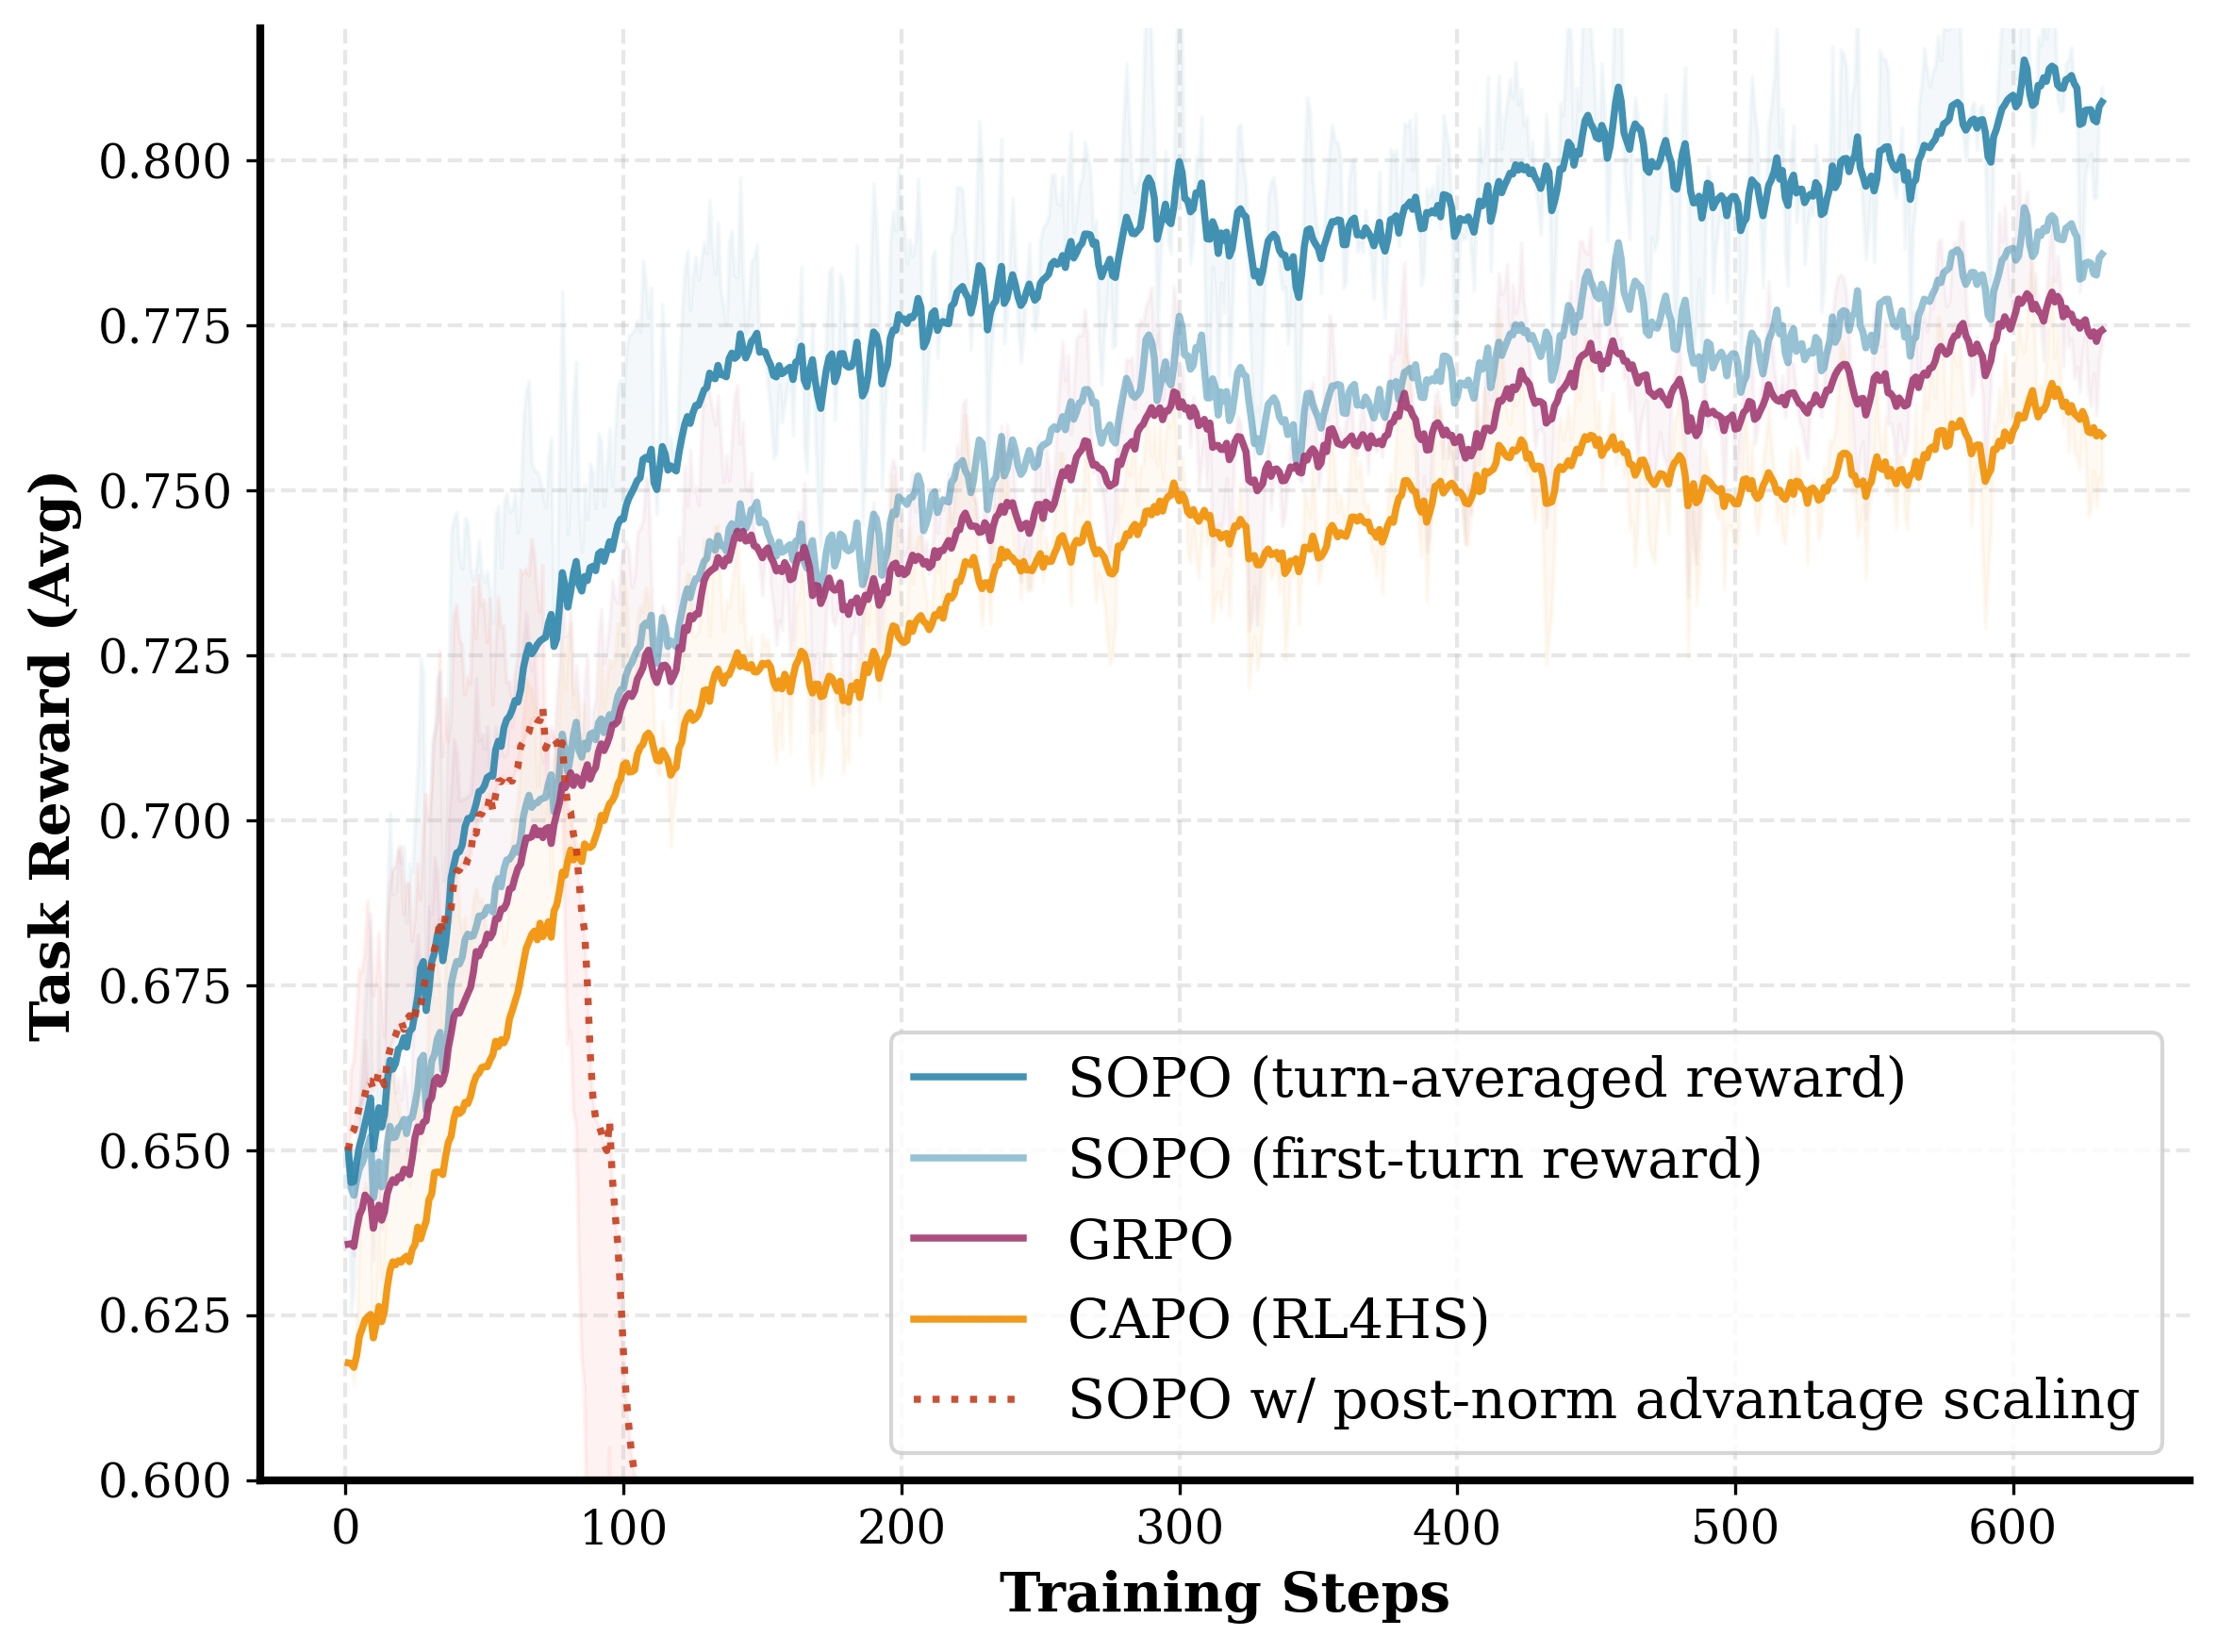

In [46]:


# 设置论文风格的图表
plt.rcParams['font.size'] = 12
plt.rcParams['font.family'] = 'serif'
plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['savefig.bbox'] = 'tight'

# 创建图表
fig, ax = plt.subplots(figsize=(8, 6))

smoothing = 0.97
smoothing_fill = 0.85
line_width = 1.8
alpha_fill = 0.05
# 绘制折线图（先绘制填充区域，再绘制平滑曲线）
if steps_sopo is not None and values_sopo is not None:
    # 计算平滑后的值
    values_sopo_smooth = smooth(values_sopo, weight=smoothing)
    values_sopo_smooth_fill = smooth(values_sopo, weight=smoothing_fill)
    values_sopo_t1_smooth = smooth(values_sopo_t1, weight=smoothing)
    # 绘制未平滑数据的波动范围（填充原始数据和平滑数据之间的区域）
    ax.fill_between(steps_sopo, values_sopo_smooth_fill, values_sopo_smooth, 
                     alpha=alpha_fill, color='#2E86AB', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_sopo, values_sopo_smooth, label='SOPO (turn-averaged reward)', linewidth=line_width, color='#2E86AB', alpha=0.9)
    ax.plot(steps_sopo_t1, values_sopo_t1_smooth, label='SOPO (first-turn reward)', linewidth=line_width, color='#2E86AB', alpha=0.5)
if steps_ori is not None and values_ori is not None:
    # 计算平滑后的值
    values_ori_smooth = smooth(values_ori, weight=smoothing)
    values_ori_smooth_fill = smooth(values_ori, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围（填充原始数据和平滑数据之间的区域）
    ax.fill_between(steps_ori, values_ori_smooth_fill, values_ori_smooth, 
                     alpha=alpha_fill, color='#A23B72', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_ori, values_ori_smooth, label='GRPO', linewidth=line_width, color='#A23B72', alpha=0.9)


    

if steps_rl4hs is not None and values_rl4hs is not None:
    # 计算平滑后的值
    values_rl4hs_smooth = smooth(values_rl4hs, weight=smoothing)
    values_rl4hs_smooth_fill = smooth(values_rl4hs, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围（填充原始数据和平滑数据之间的区域）
    ax.fill_between(steps_rl4hs, values_rl4hs_smooth_fill, values_rl4hs_smooth, 
                     alpha=alpha_fill, color='#F18F01', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_rl4hs, values_rl4hs_smooth, label='CAPO (RL4HS)', linewidth=line_width, color='#F18F01', alpha=0.9)

if steps_sopo_corrupt is not None and values_sopo_corrupt is not None:
    values_sopo_corrupt_smooth = smooth(values_sopo_corrupt, weight=smoothing)
    values_sopo_corrupt_smooth_fill = smooth(values_sopo_corrupt, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围（填充原始数据和平滑数据之间的区域）
    ax.fill_between(steps_sopo_corrupt, values_sopo_corrupt_smooth_fill, values_sopo_corrupt_smooth, 
                     alpha=alpha_fill, color='red', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_sopo_corrupt, values_sopo_corrupt_smooth, label='SOPO w/ post-norm advantage scaling', linewidth=line_width, color='#C73E1D', alpha=0.9, linestyle='dotted')

# 设置标签和标题
ax.set_xlabel('Training Steps', fontsize=14, fontweight='bold')
ax.set_ylabel('Task Reward (Avg)', fontsize=14, fontweight='bold')

plt.ylim(0.6, 0.82)
# ax.set_title('Reward Score', fontsize=16, fontweight='bold', pad=15)

# 添加GRPO平滑曲线最高点的横向虚线
# if steps_ori is not None and values_ori_smooth is not None:
#     grpo_max_value = values_ori_smooth[-1]
#     ax.axhline(y=grpo_max_value, color='#A23B72', linestyle='--', linewidth=0.8, alpha=0.7)

# 添加图例
ax.legend(loc='lower right', fontsize=14, frameon=True, fancybox=True, shadow=False)

# 添加网格
ax.grid(True, alpha=0.3, linestyle='--', linewidth=1.0)

# 美化图表
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

plt.tight_layout()

# 保存图片
output_path = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/task_reward.pdf"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"图表已保存至: {output_path}")

plt.show()


图表已保存至: /mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/entropy.pdf


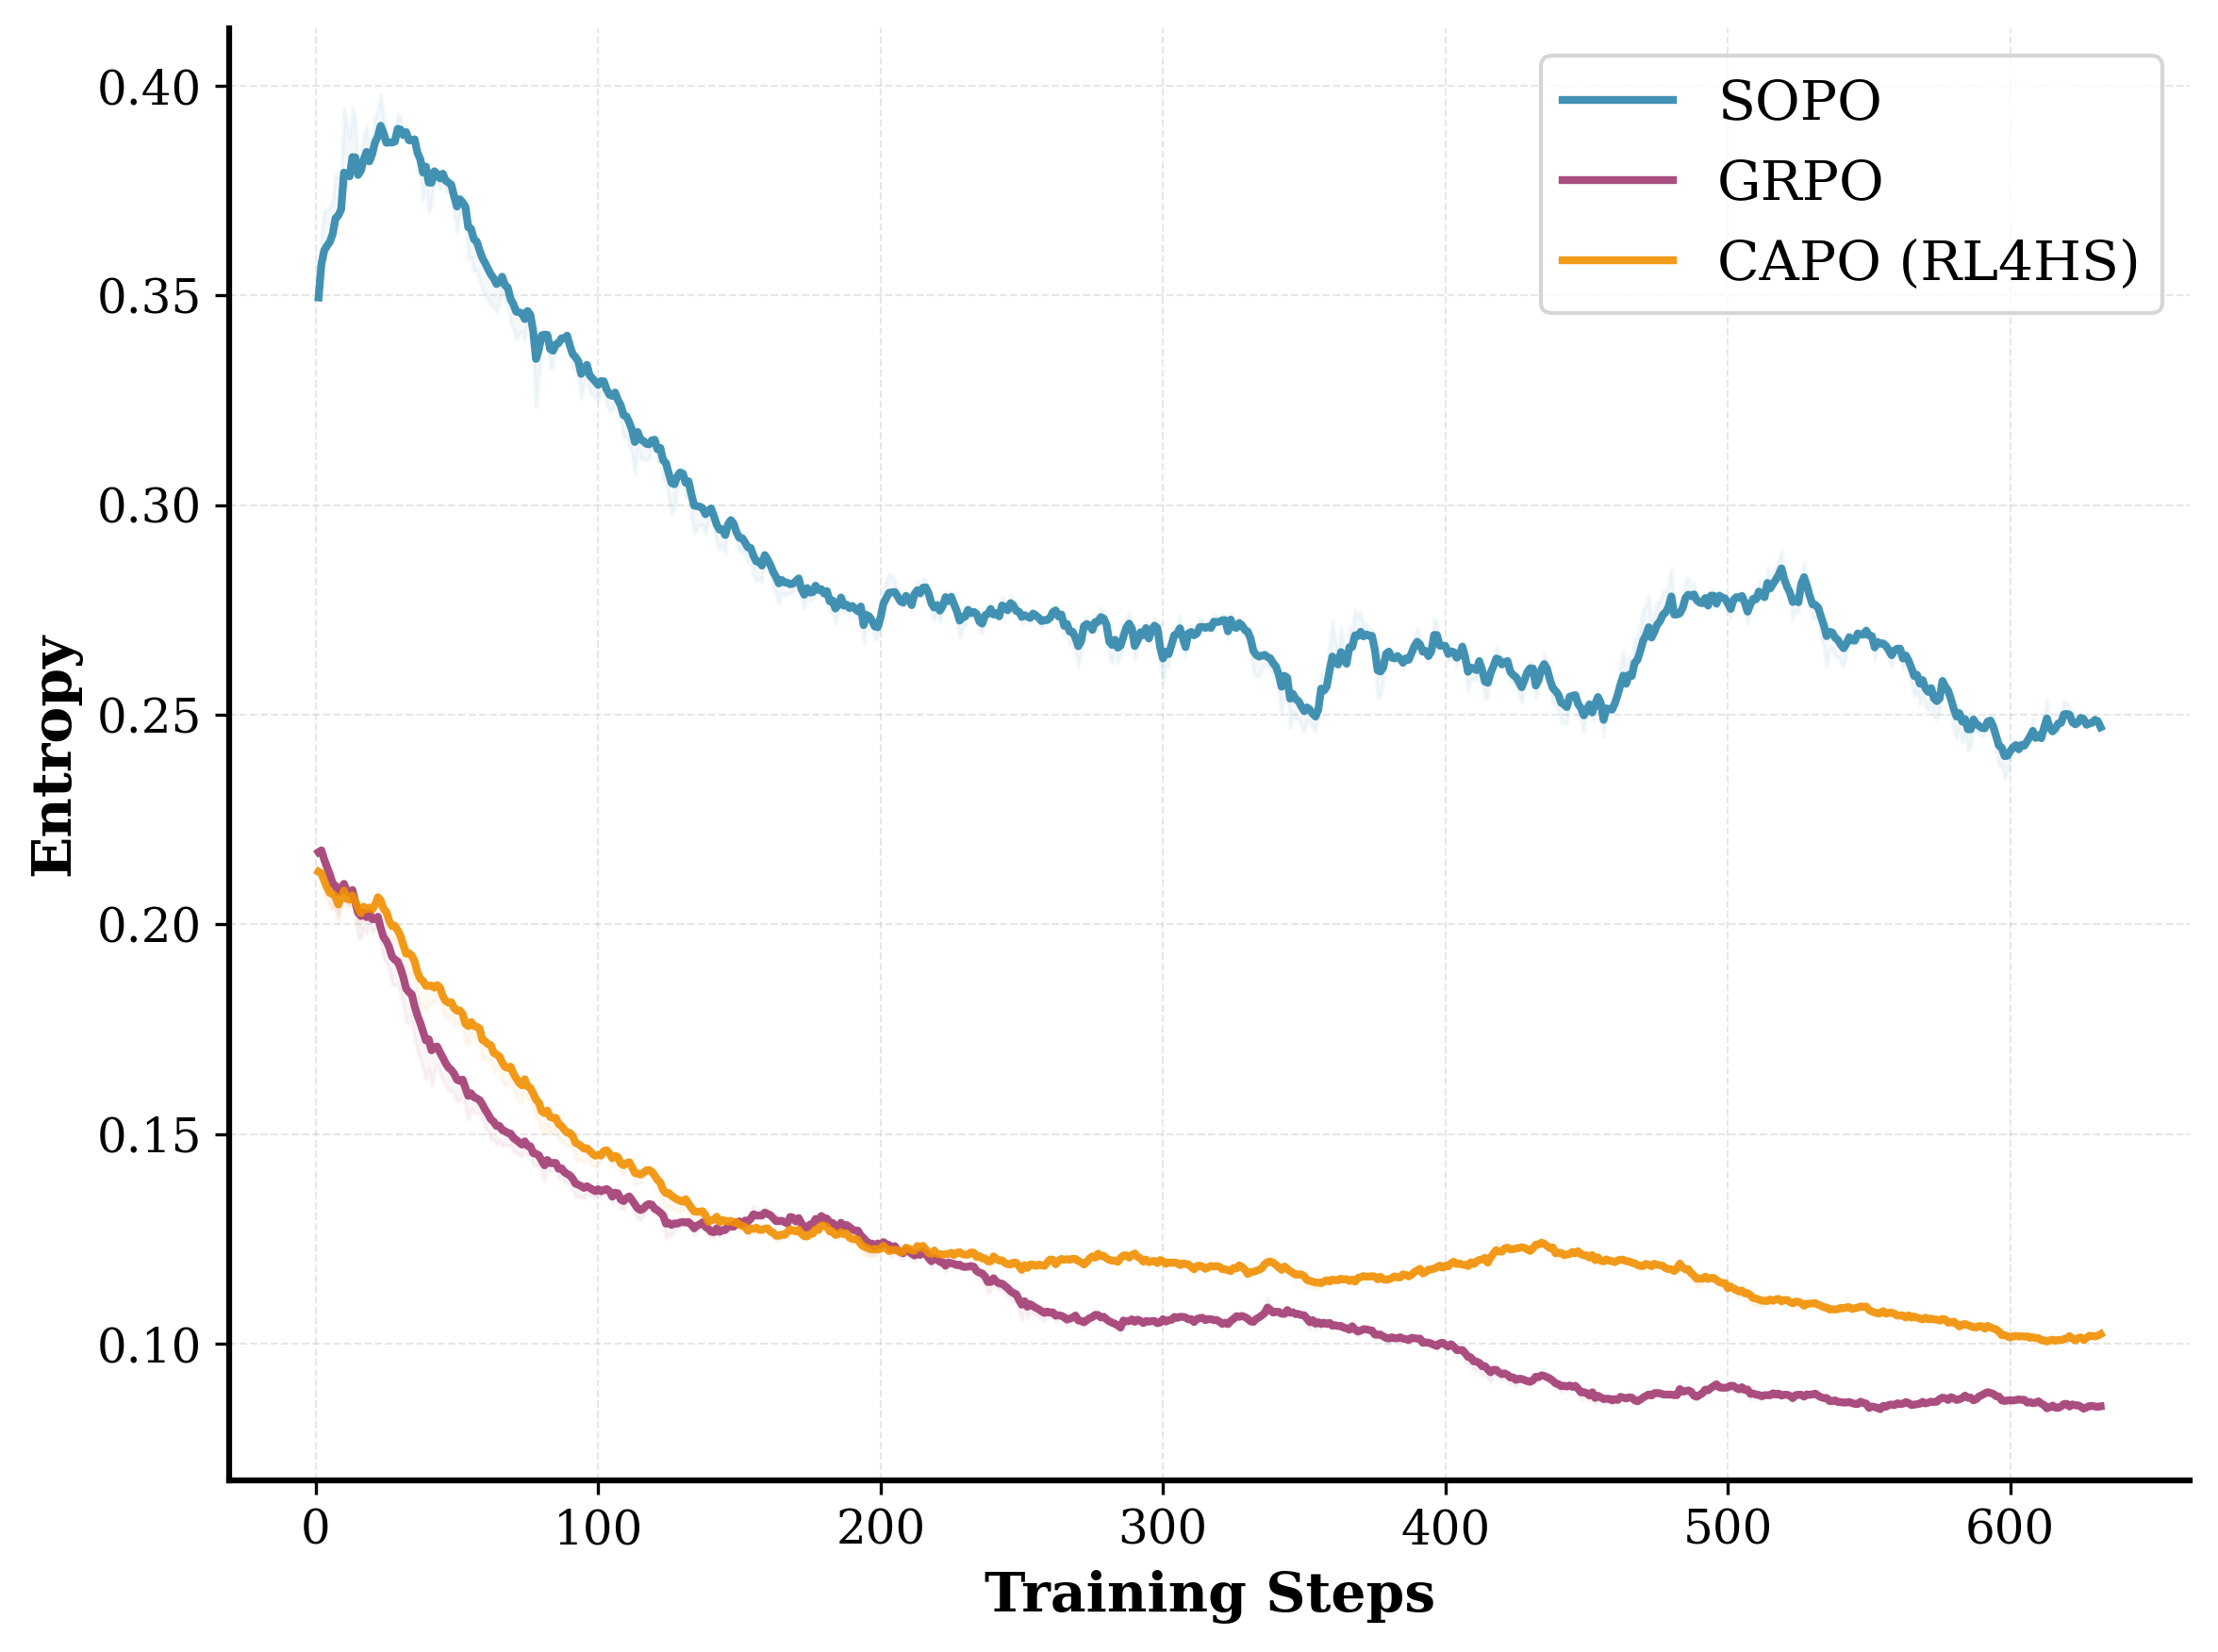

In [48]:
# 绘制Entropy折线图
fig, ax = plt.subplots(figsize=(8, 6))

smoothing = 0.9
smoothing_fill = 0.80
line_width = 2.0
alpha_fill = 0.05

# 绘制折线图（先绘制填充区域，再绘制平滑曲线）
if steps_sopo_entropy is not None and values_sopo_entropy is not None:
    # 计算平滑后的值
    values_sopo_entropy_smooth = smooth(values_sopo_entropy, weight=smoothing)
    values_sopo_entropy_smooth_fill = smooth(values_sopo_entropy, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_sopo_entropy, values_sopo_entropy_smooth_fill, values_sopo_entropy_smooth, 
                     alpha=alpha_fill, color='#2E86AB', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_sopo_entropy, values_sopo_entropy_smooth, label='SOPO', linewidth=line_width, color='#2E86AB', alpha=0.9)

if steps_ori_entropy is not None and values_ori_entropy is not None:
    # 计算平滑后的值
    values_ori_entropy_smooth = smooth(values_ori_entropy, weight=smoothing)
    values_ori_entropy_smooth_fill = smooth(values_ori_entropy, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_ori_entropy, values_ori_entropy_smooth_fill, values_ori_entropy_smooth, 
                     alpha=alpha_fill, color='#A23B72', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_ori_entropy, values_ori_entropy_smooth, label='GRPO', linewidth=line_width, color='#A23B72', alpha=0.9)

if steps_rl4hs_entropy is not None and values_rl4hs_entropy is not None:
    # 计算平滑后的值
    values_rl4hs_entropy_smooth = smooth(values_rl4hs_entropy, weight=smoothing)
    values_rl4hs_entropy_smooth_fill = smooth(values_rl4hs_entropy, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_rl4hs_entropy, values_rl4hs_entropy_smooth_fill, values_rl4hs_entropy_smooth, 
                     alpha=alpha_fill, color='#F18F01', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_rl4hs_entropy, values_rl4hs_entropy_smooth, label='CAPO (RL4HS)', linewidth=line_width, color='#F18F01', alpha=0.9)

# 设置标签和标题
ax.set_xlabel('Training Steps', fontsize=14, fontweight='bold')
ax.set_ylabel('Entropy', fontsize=14, fontweight='bold')

# 添加图例
ax.legend(loc='best', fontsize=14, frameon=True, fancybox=True, shadow=False)

# 添加网格
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

# 美化图表
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()

# 保存图片
output_path = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/entropy.pdf"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"图表已保存至: {output_path}")

plt.show()


图表已保存至: /mnt/cpfs2/dongjiawei/projects/rl/AReaL_20251111_040/plot/grad_norm.pdf


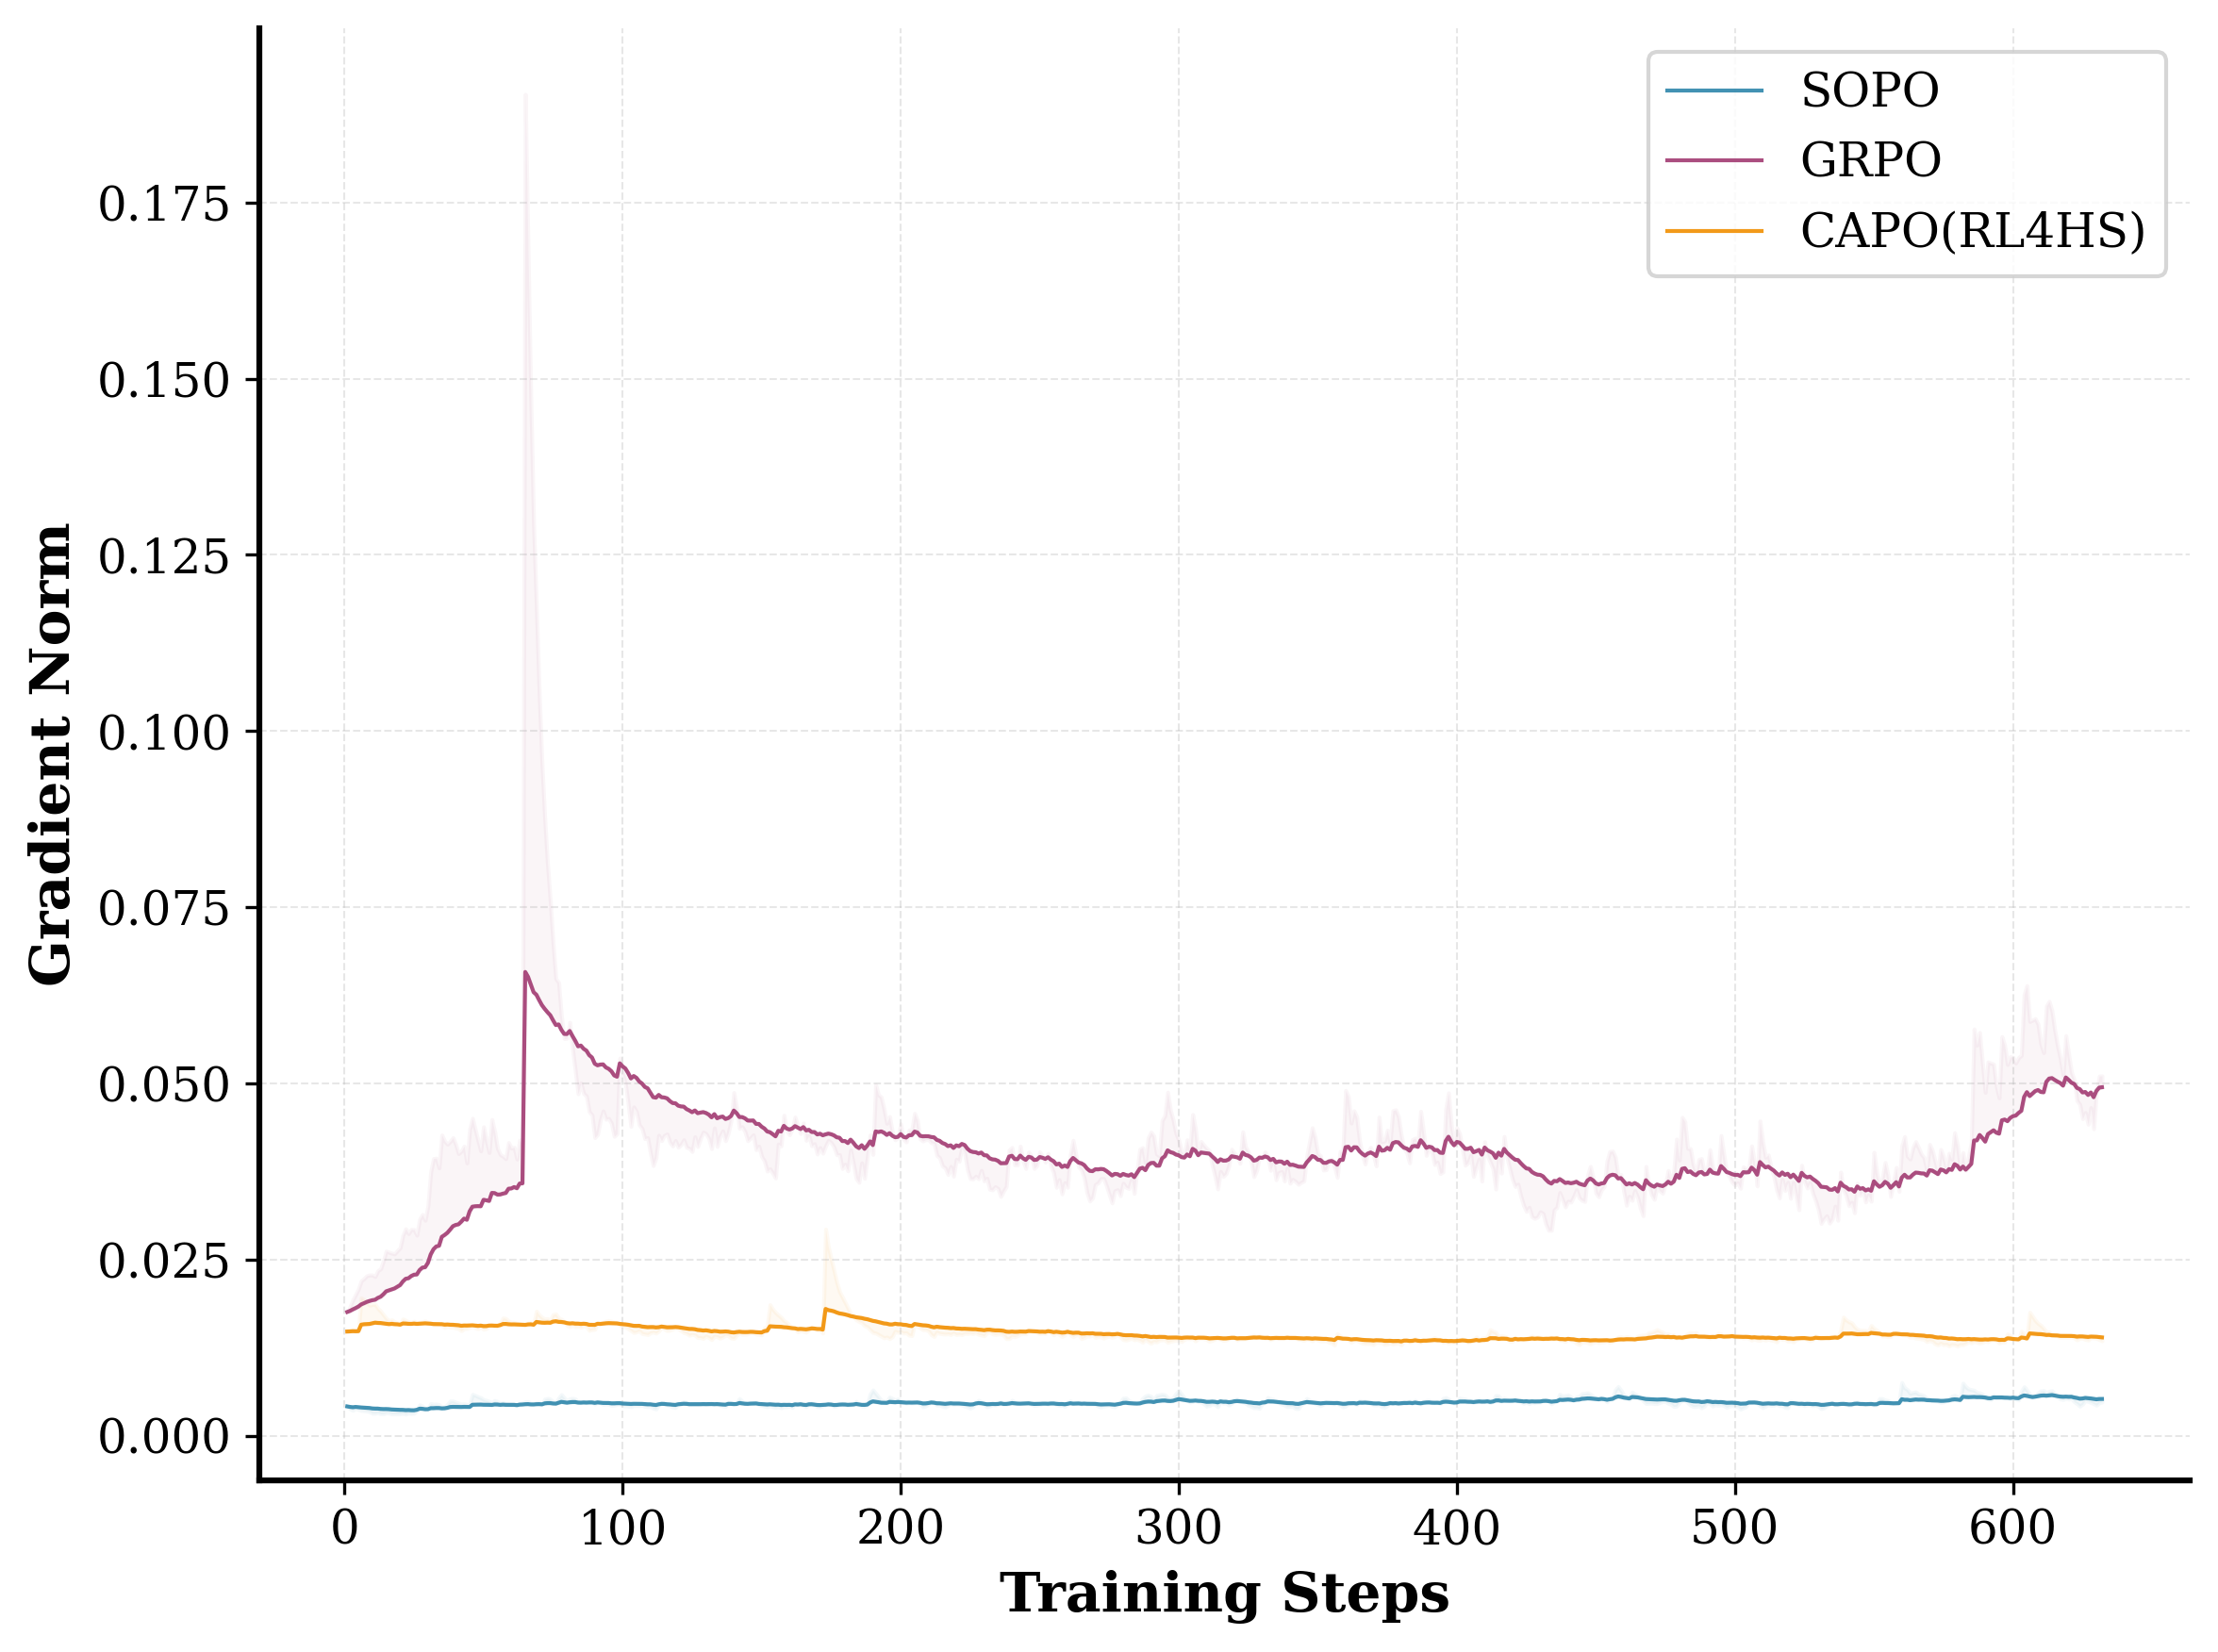

In [6]:
# 绘制Gradient Norm折线图
fig, ax = plt.subplots(figsize=(8, 6))

smoothing = 0.97
smoothing_fill = 0.85
line_width = 1.0
alpha_fill = 0.05

# 绘制折线图（先绘制填充区域，再绘制平滑曲线）
if steps_sopo_grad is not None and values_sopo_grad is not None:
    # 计算平滑后的值
    values_sopo_grad_smooth = smooth(values_sopo_grad, weight=smoothing)
    values_sopo_grad_smooth_fill = smooth(values_sopo_grad, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_sopo_grad, values_sopo_grad_smooth_fill, values_sopo_grad_smooth, 
                     alpha=alpha_fill, color='#2E86AB', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_sopo_grad, values_sopo_grad_smooth, label='SOPO', linewidth=line_width, color='#2E86AB', alpha=0.9)

if steps_ori_grad is not None and values_ori_grad is not None:
    # 计算平滑后的值
    values_ori_grad_smooth = smooth(values_ori_grad, weight=smoothing)
    values_ori_grad_smooth_fill = smooth(values_ori_grad, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_ori_grad, values_ori_grad_smooth_fill, values_ori_grad_smooth, 
                     alpha=alpha_fill, color='#A23B72', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_ori_grad, values_ori_grad_smooth, label='GRPO', linewidth=line_width, color='#A23B72', alpha=0.9)

if steps_rl4hs_grad is not None and values_rl4hs_grad is not None:
    # 计算平滑后的值
    values_rl4hs_grad_smooth = smooth(values_rl4hs_grad, weight=smoothing)
    values_rl4hs_grad_smooth_fill = smooth(values_rl4hs_grad, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_rl4hs_grad, values_rl4hs_grad_smooth_fill, values_rl4hs_grad_smooth, 
                     alpha=alpha_fill, color='#F18F01', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_rl4hs_grad, values_rl4hs_grad_smooth, label='CAPO(RL4HS)', linewidth=line_width, color='#F18F01', alpha=0.9)

# 设置标签和标题
ax.set_xlabel('Training Steps', fontsize=14, fontweight='bold')
ax.set_ylabel('Gradient Norm', fontsize=14, fontweight='bold')

# 添加图例
ax.legend(loc='best', fontsize=12, frameon=True, fancybox=True, shadow=False)

# 添加网格
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

# 美化图表
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()

# 保存图片
output_path = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/grad_norm.pdf"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"图表已保存至: {output_path}")

plt.show()

In [36]:
# 对齐seq_len和turns数据，并计算seq_len/turns
# 对于每个数据集，需要对齐seq_len和turns的step，然后计算比值

def align_and_compute_ratio(steps_seq_len, values_seq_len, steps_turns, values_turns):
    """对齐seq_len和turns数据，并计算seq_len/turns"""
    if steps_seq_len is None or values_seq_len is None or steps_turns is None or values_turns is None:
        return None, None
    
    # 找到共同的step范围
    common_steps = np.intersect1d(steps_seq_len, steps_turns)
    if len(common_steps) == 0:
        return None, None
    
    # 获取对应的值
    seq_len_aligned = np.array([values_seq_len[steps_seq_len == step][0] for step in common_steps])
    turns_aligned = np.array([values_turns[steps_turns == step][0] for step in common_steps])
    
    # 计算比值，避免除零
    ratio = np.divide(seq_len_aligned, turns_aligned, out=np.zeros_like(seq_len_aligned), where=turns_aligned!=0)
    
    return common_steps, ratio

# 计算seq_len/turns
steps_sopo_n8_ratio, values_sopo_n8_ratio = align_and_compute_ratio(
    steps_sopo_n8_seq_len, values_sopo_n8_seq_len, steps_sopo_n8_turns, values_sopo_n8_turns)
steps_ori_ratio, values_ori_ratio = align_and_compute_ratio(
    steps_ori_seq_len, values_ori_seq_len, steps_ori_turns, values_ori_turns)
steps_rl4hs_ratio, values_rl4hs_ratio = align_and_compute_ratio(
    steps_rl4hs_seq_len, values_rl4hs_seq_len, steps_rl4hs_turns, values_rl4hs_turns)

# 对齐所有数据集到最小长度
if steps_sopo_n8_ratio is not None and steps_ori_ratio is not None and steps_rl4hs_ratio is not None:
    min_length_ratio = min(len(steps_sopo_n8_ratio), len(steps_ori_ratio), len(steps_rl4hs_ratio))
    steps_sopo_n8_ratio = steps_sopo_n8_ratio[:min_length_ratio]
    values_sopo_n8_ratio = values_sopo_n8_ratio[:min_length_ratio]
    steps_ori_ratio = steps_ori_ratio[:min_length_ratio]
    values_ori_ratio = values_ori_ratio[:min_length_ratio]
    steps_rl4hs_ratio = steps_rl4hs_ratio[:min_length_ratio]
    values_rl4hs_ratio = values_rl4hs_ratio[:min_length_ratio]
    print(f"对齐后: seq_len/turns数据有 {min_length_ratio} 个数据点")
elif steps_sopo_n8_ratio is not None and steps_ori_ratio is not None:
    min_length_ratio = min(len(steps_sopo_n8_ratio), len(steps_ori_ratio))
    steps_sopo_n8_ratio = steps_sopo_n8_ratio[:min_length_ratio]
    values_sopo_n8_ratio = values_sopo_n8_ratio[:min_length_ratio]
    steps_ori_ratio = steps_ori_ratio[:min_length_ratio]
    values_ori_ratio = values_ori_ratio[:min_length_ratio]
    print(f"对齐后: seq_len/turns数据有 {min_length_ratio} 个数据点")




对齐后: seq_len/turns数据有 618 个数据点


图表已保存至: /mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/seq_len_turns_ratio.pdf


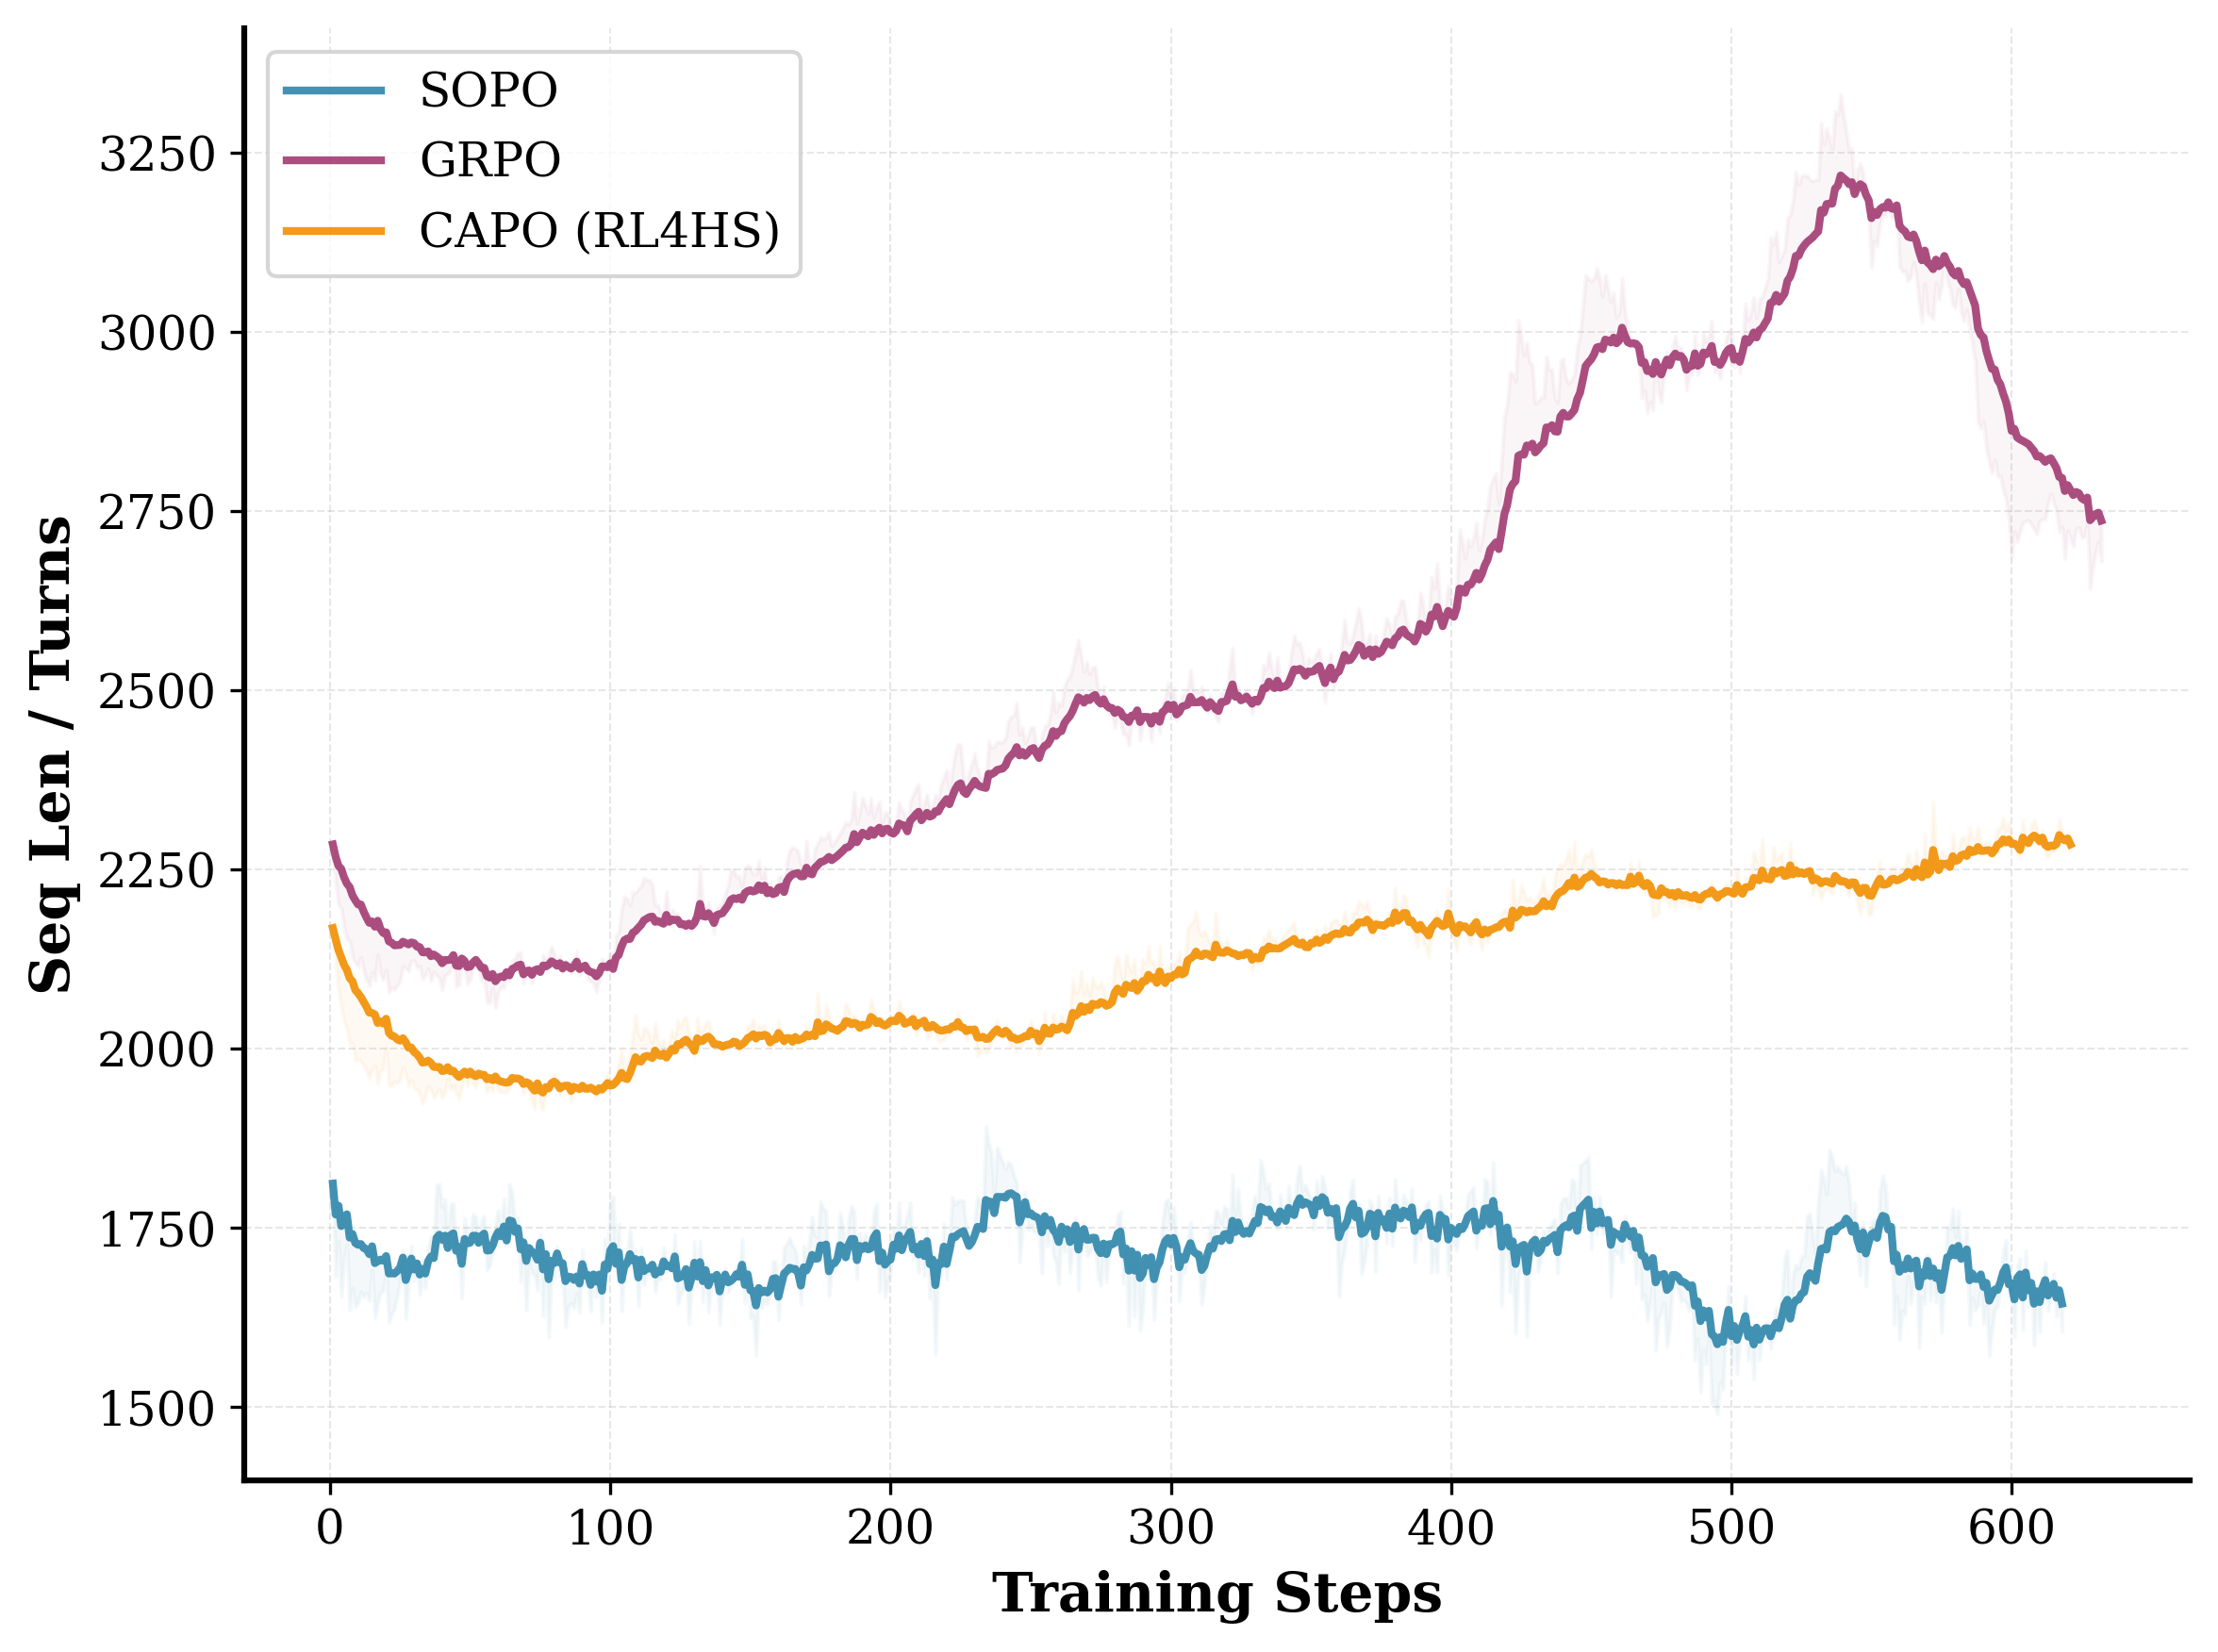

In [38]:
# 绘制Seq Len / Turns折线图
fig, ax = plt.subplots(figsize=(8, 6))

smoothing = 0.95
smoothing_fill = 0.85
line_width = 2
alpha_fill = 0.05

# 绘制折线图（先绘制填充区域，再绘制平滑曲线）
if steps_sopo_n8_ratio is not None and values_sopo_n8_ratio is not None:
    # 计算平滑后的值
    values_sopo_n8_ratio_smooth = smooth(values_sopo_n8_ratio, weight=smoothing)
    values_sopo_n8_ratio_smooth_fill = smooth(values_sopo_n8_ratio, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_sopo_n8_ratio, values_sopo_n8_ratio_smooth_fill, values_sopo_n8_ratio_smooth, 
                     alpha=alpha_fill, color='#2E86AB', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_sopo_n8_ratio, values_sopo_n8_ratio_smooth, label='SOPO', linewidth=line_width, color='#2E86AB', alpha=0.9)

if steps_ori_ratio is not None and values_ori_ratio is not None:
    # 计算平滑后的值
    values_ori_ratio_smooth = smooth(values_ori_ratio, weight=smoothing)
    values_ori_ratio_smooth_fill = smooth(values_ori_ratio, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_ori_ratio, values_ori_ratio_smooth_fill, values_ori_ratio_smooth, 
                     alpha=alpha_fill, color='#A23B72', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_ori_ratio, values_ori_ratio_smooth, label='GRPO', linewidth=line_width, color='#A23B72', alpha=0.9)

if steps_rl4hs_ratio is not None and values_rl4hs_ratio is not None:
    # 计算平滑后的值
    values_rl4hs_ratio_smooth = smooth(values_rl4hs_ratio, weight=smoothing)
    values_rl4hs_ratio_smooth_fill = smooth(values_rl4hs_ratio, weight=smoothing_fill)
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_rl4hs_ratio, values_rl4hs_ratio_smooth_fill, values_rl4hs_ratio_smooth, 
                     alpha=alpha_fill, color='#F18F01', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_rl4hs_ratio, values_rl4hs_ratio_smooth, label='CAPO (RL4HS)', linewidth=line_width, color='#F18F01', alpha=0.9)

# 设置标签和标题
ax.set_xlabel('Training Steps', fontsize=14, fontweight='bold')
ax.set_ylabel('Seq Len / Turns', fontsize=14, fontweight='bold')

# 添加图例
ax.legend(loc='best', fontsize=12, frameon=True, fancybox=True, shadow=False)

# 添加网格
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

# 美化图表
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()

# 保存图片
output_path = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/seq_len_turns_ratio.pdf"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"图表已保存至: {output_path}")

plt.show()


# Socratic Ablation 

Analysis Only: 948 data points
Guidance Only: 948 data points
Spoiler: 948 data points
SOPO (original): 948 data points
对齐后: reward数据有 632 个数据点
图表已保存至: /mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/socratic_ablation_task_reward.pdf


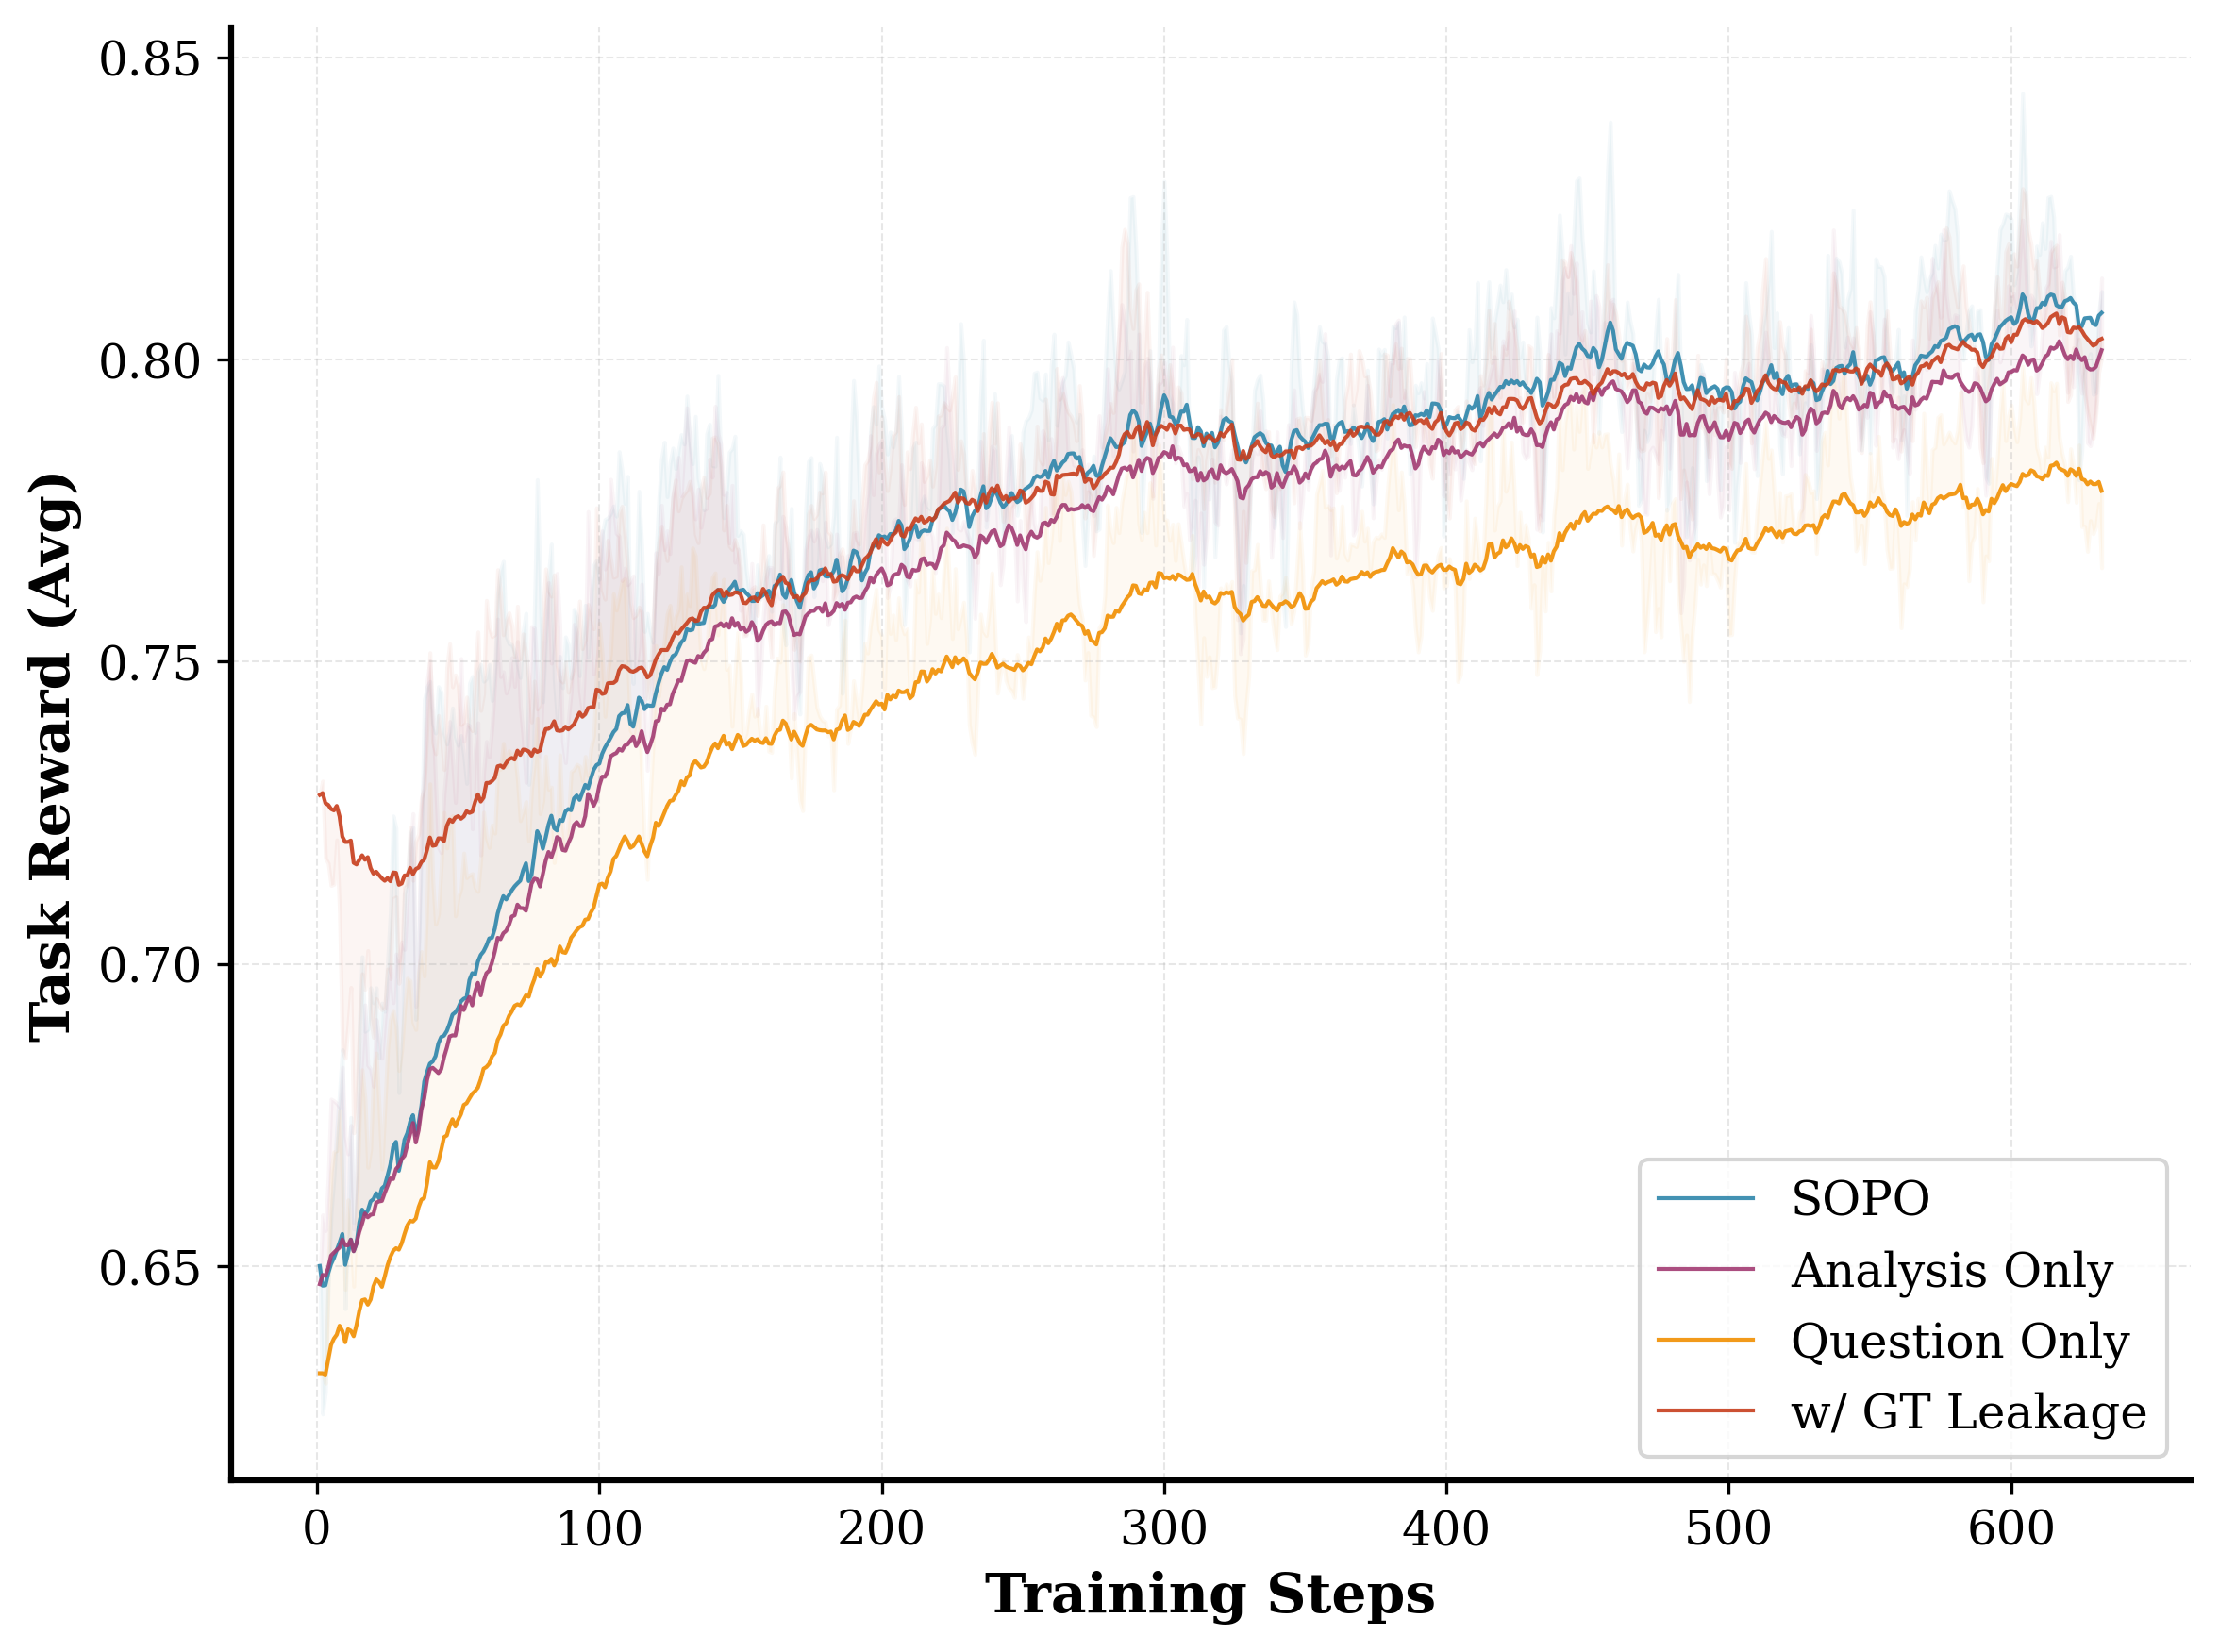

In [52]:
# 加载Socratic Ablation数据
metric_name = "ppo_actor/task_reward/avg"

steps_analysis_only, values_analysis_only = load_tensorboard_scalar(tb_analysis_only, metric_name)
steps_guidance_only, values_guidance_only = load_tensorboard_scalar(tb_guidance_only, metric_name)
steps_spoiler, values_spoiler = load_tensorboard_scalar(tb_spoiler, metric_name)
steps_sopo_ablation, values_sopo_ablation = load_tensorboard_scalar(tb_sopo, metric_name)

print(f"Analysis Only: {len(steps_analysis_only) if steps_analysis_only is not None else 0} data points")
print(f"Guidance Only: {len(steps_guidance_only) if steps_guidance_only is not None else 0} data points")
print(f"Spoiler: {len(steps_spoiler) if steps_spoiler is not None else 0} data points")
print(f"SOPO (original): {len(steps_sopo_ablation) if steps_sopo_ablation is not None else 0} data points")

# 对齐数据：以最小的step数量为上限
valid_lengths = []
if steps_analysis_only is not None:
    valid_lengths.append(len(steps_analysis_only))
if steps_guidance_only is not None:
    valid_lengths.append(len(steps_guidance_only))
if steps_spoiler is not None:
    valid_lengths.append(len(steps_spoiler))
if steps_sopo_ablation is not None:
    valid_lengths.append(len(steps_sopo_ablation))



if valid_lengths:
    min_length_ablation = min(valid_lengths)
    min_length_ablation = 632
    if steps_analysis_only is not None:
        steps_analysis_only = steps_analysis_only[:min_length_ablation]
        values_analysis_only = values_analysis_only[:min_length_ablation]
    if steps_guidance_only is not None:
        steps_guidance_only = steps_guidance_only[:min_length_ablation]
        values_guidance_only = values_guidance_only[:min_length_ablation]
    if steps_spoiler is not None:
        steps_spoiler = steps_spoiler[:min_length_ablation]
        values_spoiler = values_spoiler[:min_length_ablation]
    if steps_sopo_ablation is not None:
        steps_sopo_ablation = steps_sopo_ablation[:min_length_ablation]
        values_sopo_ablation = values_sopo_ablation[:min_length_ablation]
    
    print(f"对齐后: reward数据有 {min_length_ablation} 个数据点")

# 绘制Socratic Ablation对比图
fig, ax = plt.subplots(figsize=(8, 6))

ss = 632

smoothing = 0.98
smoothing_fill = 0.85
line_width = 1.0
alpha_fill = 0.05
values_sopo_ablation[0] = 0.65
# 绘制折线图（先绘制填充区域，再绘制平滑曲线）
if steps_sopo_ablation is not None and values_sopo_ablation is not None:
    # 计算平滑后的值
    values_sopo_ablation_smooth = smooth(values_sopo_ablation, weight=smoothing)[:ss]
    values_sopo_ablation_smooth_fill = smooth(values_sopo_ablation, weight=smoothing_fill)[:ss]



    # 绘制未平滑数据的波动范围（填充原始数据和平滑数据之间的区域）
    ax.fill_between(steps_sopo_ablation, values_sopo_ablation_smooth_fill, values_sopo_ablation_smooth, 
                     alpha=alpha_fill, color='#2E86AB', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_sopo_ablation, values_sopo_ablation_smooth, label='SOPO', linewidth=line_width, color='#2E86AB', alpha=0.9)

if steps_analysis_only is not None and values_analysis_only is not None:
    # 计算平滑后的值
    values_analysis_only_smooth = smooth(values_analysis_only, weight=smoothing)[:ss]
    values_analysis_only_smooth_fill = smooth(values_analysis_only, weight=smoothing_fill)[:ss]
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_analysis_only, values_analysis_only_smooth_fill, values_analysis_only_smooth, 
                     alpha=alpha_fill, color='#A23B72', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_analysis_only, values_analysis_only_smooth, label='Analysis Only', linewidth=line_width, color='#A23B72', alpha=0.9)

if steps_guidance_only is not None and values_guidance_only is not None:
    # 计算平滑后的值
    values_guidance_only_smooth = smooth(values_guidance_only, weight=smoothing)[:ss]
    values_guidance_only_smooth_fill = smooth(values_guidance_only, weight=smoothing_fill)[:ss]
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_guidance_only, values_guidance_only_smooth_fill, values_guidance_only_smooth, 
                     alpha=alpha_fill, color='#F18F01', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_guidance_only, values_guidance_only_smooth, label='Question Only', linewidth=line_width, color='#F18F01', alpha=0.9)

if steps_spoiler is not None and values_spoiler is not None:
    # 计算平滑后的值
    values_spoiler_smooth = smooth(values_spoiler, weight=smoothing)[:ss]
    values_spoiler_smooth_fill = smooth(values_spoiler, weight=smoothing_fill)[:ss]
    # 绘制未平滑数据的波动范围
    ax.fill_between(steps_spoiler, values_spoiler_smooth_fill, values_spoiler_smooth, 
                     alpha=alpha_fill, color='#C73E1D', label='_nolegend_', where=None, interpolate=True)
    # 绘制平滑后的曲线
    ax.plot(steps_spoiler, values_spoiler_smooth, label='w/ GT Leakage', linewidth=line_width, color='#C73E1D', alpha=0.9)

# 设置标签和标题
ax.set_xlabel('Training Steps', fontsize=14, fontweight='bold')
ax.set_ylabel('Task Reward (Avg)', fontsize=14, fontweight='bold')

# 添加图例
ax.legend(loc='lower right', fontsize=12, frameon=True, fancybox=True, shadow=False)

# 添加网格
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

# 美化图表
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()
# plt.ylim(0.6, 0.83)
# 保存图片
output_path = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/socratic_ablation_task_reward.pdf"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"图表已保存至: {output_path}")

plt.show()

### SOPO under exact DS settings

SOPO (Dynamic Sampling off): 943 data points
SOPO (Dynamic Sampling on): 948 data points
GRPO (Dynamic Sampling off): 632 data points
GRPO (Dynamic Sampling on): 708 data points
图表已保存至: /mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/task_reward_4_methods.png


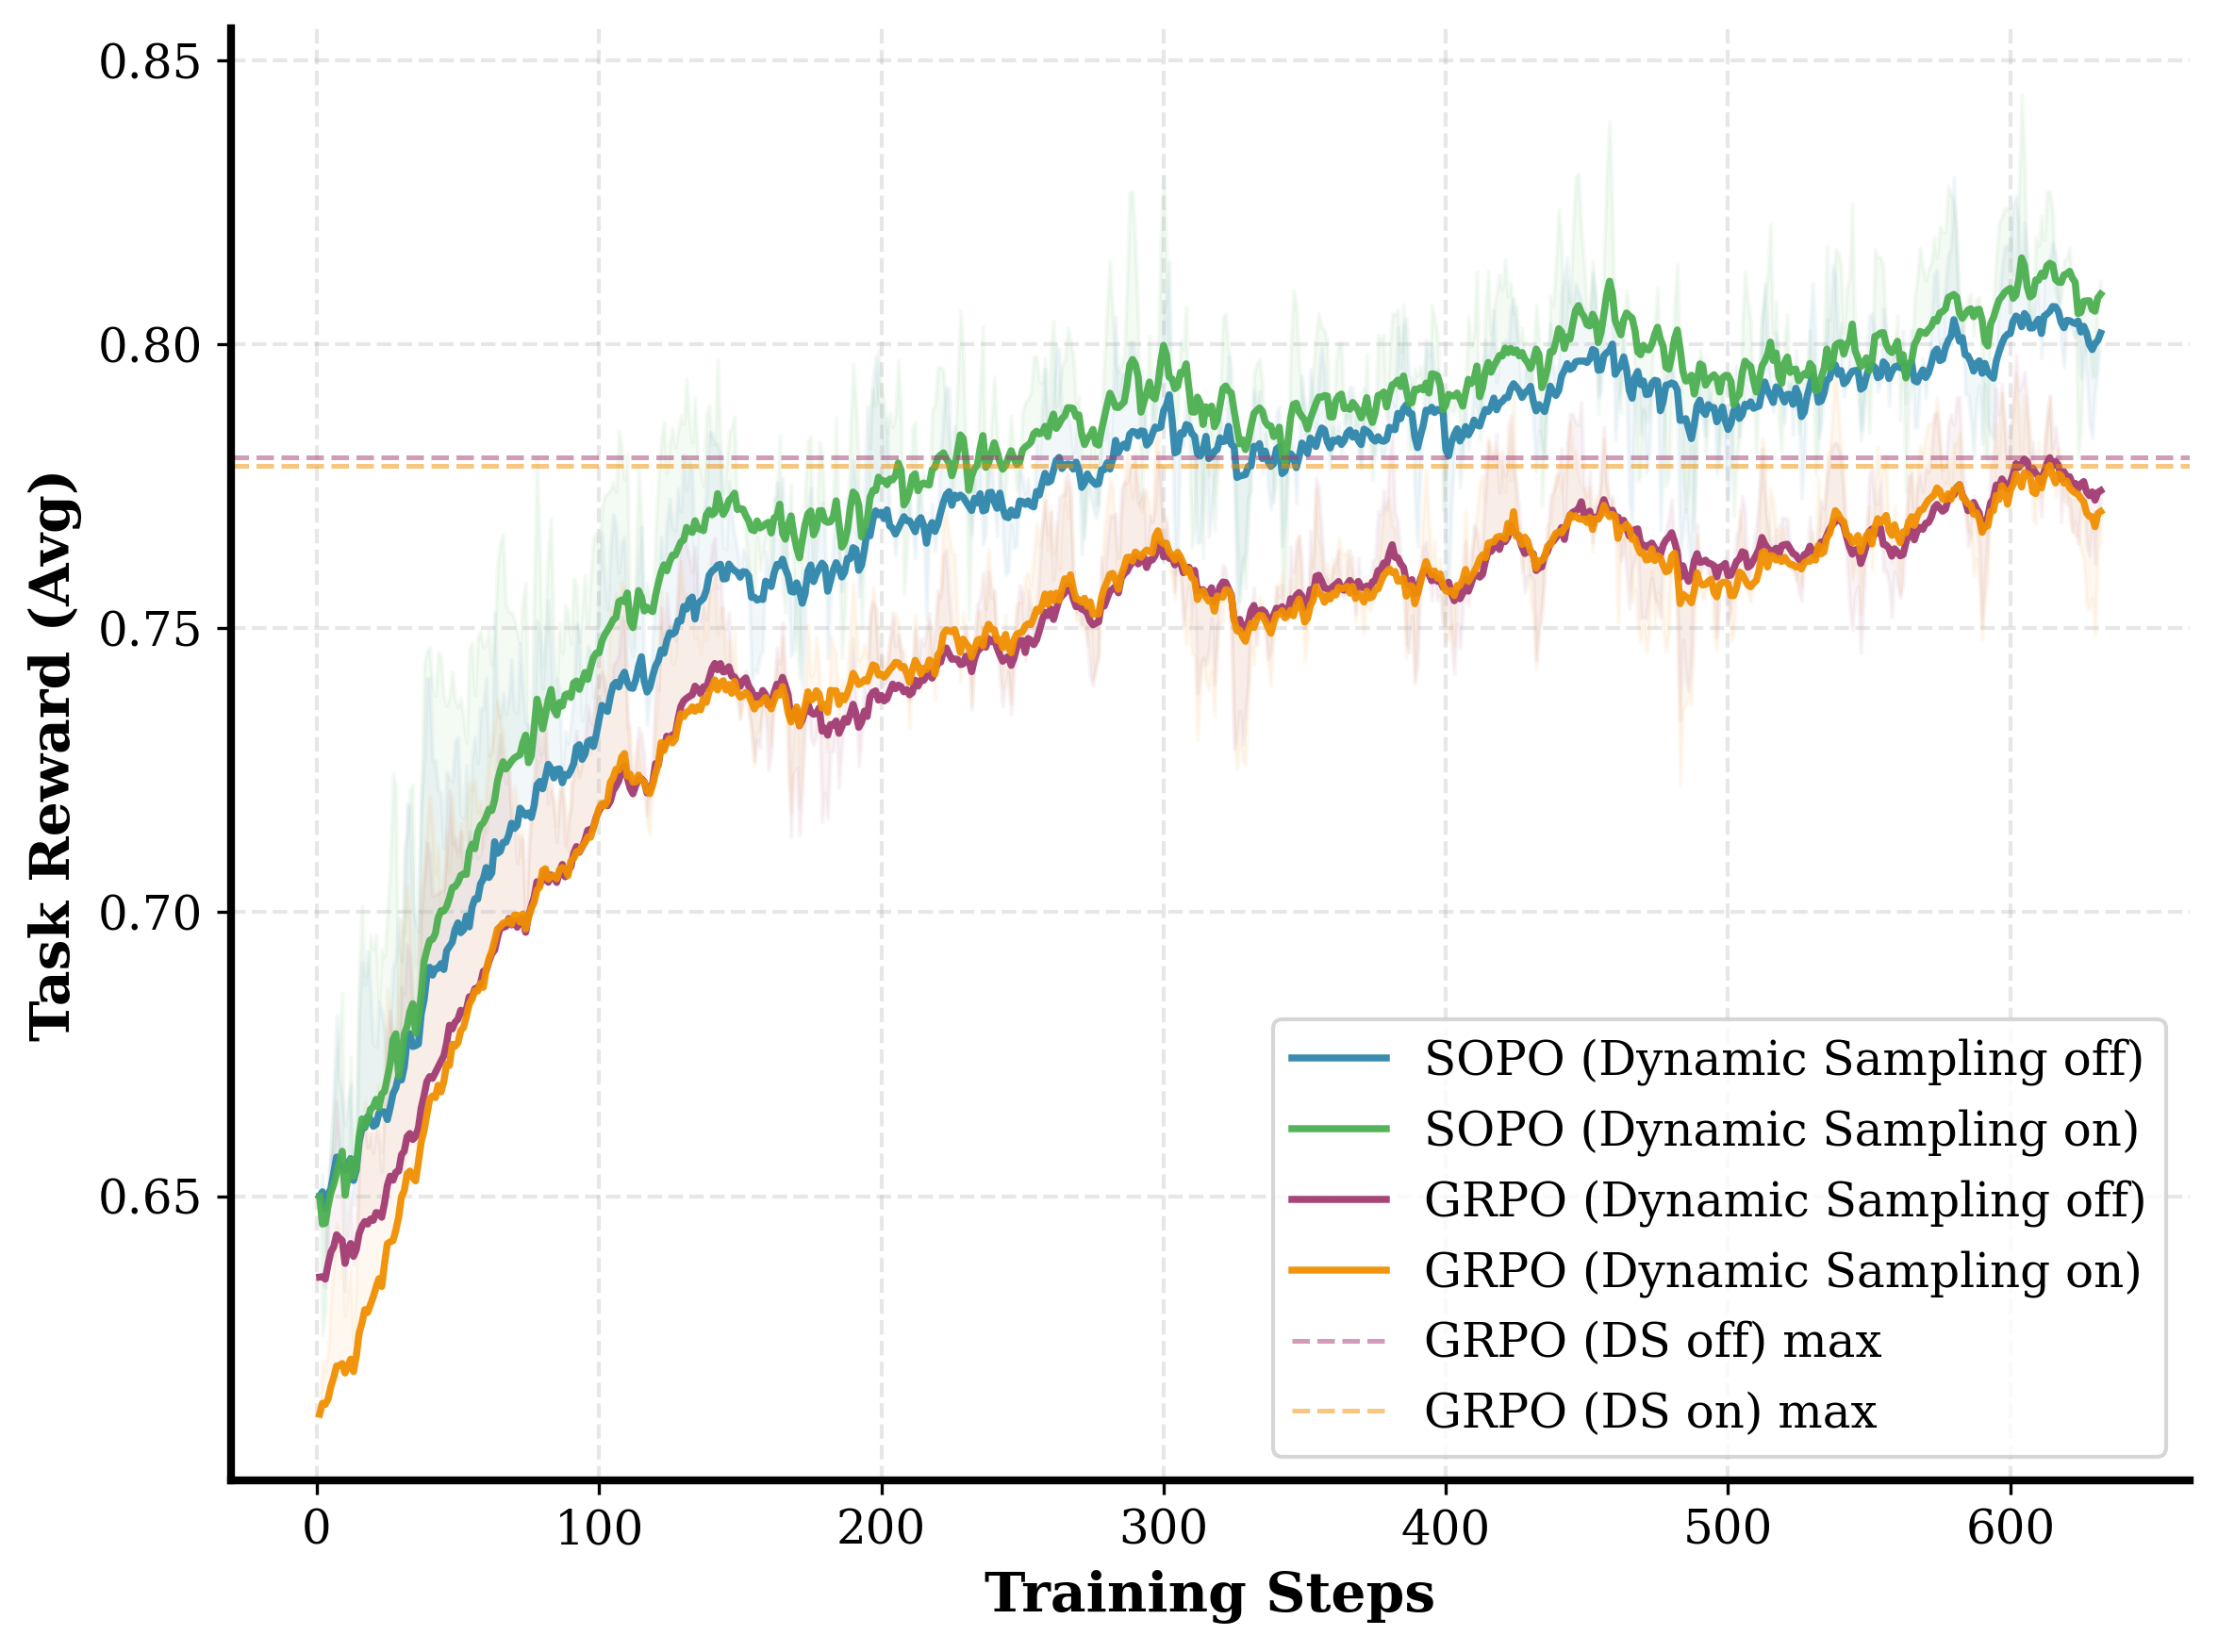

In [15]:
tb_sopo = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20260402_ragtruth_10k_fb_ds_off"
tb_sopo_ds = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251219_ragtruth_10k_fb_rand_prompt_next_nr24_norm_after_scaling"
tb_ori = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251211_ragtruth_10k_ori"
tb_ori_ds = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20260401_ori_ds"

metric_name = "ppo_actor/task_reward/avg"

steps_sopo, values_sopo = load_tensorboard_scalar(tb_sopo, metric_name)
steps_sopo_ds, values_sopo_ds = load_tensorboard_scalar(tb_sopo_ds, metric_name)
steps_ori, values_ori = load_tensorboard_scalar(tb_ori, metric_name)
steps_ori_ds, values_ori_ds = load_tensorboard_scalar(tb_ori_ds, metric_name)

values_sopo_ds[0] = 0.65
values_sopo[0] = 0.65

# 设置论文风格的图表
plt.rcParams['font.size'] = 12
plt.rcParams['font.family'] = 'serif'
plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['savefig.bbox'] = 'tight'

fig, ax = plt.subplots(figsize=(8, 6))

smoothing = 0.97
smoothing_fill = 0.85
line_width = 1.8
alpha_fill = 0.06

series = [
    ("SOPO (Dynamic Sampling off)", steps_sopo, values_sopo, "#2E86AB"),
    ("SOPO (Dynamic Sampling on)", steps_sopo_ds, values_sopo_ds, "#4CAF50"),
    ("GRPO (Dynamic Sampling off)", steps_ori, values_ori, "#A23B72"),
    ("GRPO (Dynamic Sampling on)", steps_ori_ds, values_ori_ds, "#F18F01"),
]

max_points = 632
grpo_max_value = None
grpo_ds_max_value = None

for label, steps, values, color in series:
    n_points = len(steps) if steps is not None else 0
    print(f"{label}: {n_points} data points")
    if steps is None or values is None or len(values) == 0:
        continue

    steps = steps[:max_points]
    values = values[:max_points]

    values_smooth = smooth(values, weight=smoothing)
    values_smooth_fill = smooth(values, weight=smoothing_fill)
    ax.fill_between(
        steps,
        values_smooth_fill,
        values_smooth,
        alpha=alpha_fill,
        color=color,
        label='_nolegend_',
        where=None,
        interpolate=True,
    )
    ax.plot(
        steps,
        values_smooth,
        label=f"{label}",
        linewidth=line_width,
        color=color,
        alpha=0.95,
    )

    if label == "GRPO (Dynamic Sampling off)":
        grpo_max_value = float(np.max(values_smooth))
    if label == "GRPO (Dynamic Sampling on)":
        grpo_ds_max_value = float(np.max(values_smooth))

if grpo_max_value is not None:
    ax.axhline(
        y=grpo_max_value,
        color="#A23B72",
        linestyle="--",
        linewidth=1.2,
        alpha=0.5,
        label="GRPO (DS off) max",
    )
if grpo_ds_max_value is not None:
    ax.axhline(
        y=grpo_ds_max_value,
        color="#F18F01",
        linestyle="--",
        linewidth=1.2,
        alpha=0.5,
        label="GRPO (DS on) max",
    )

ax.set_xlabel('Training Steps', fontsize=14, fontweight='bold')
ax.set_ylabel('Task Reward (Avg)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=12, frameon=True, fancybox=True, shadow=False)
ax.grid(True, alpha=0.3, linestyle='--', linewidth=1.0)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

plt.tight_layout()

output_path = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/task_reward_4_methods.pdf"
output_path = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/task_reward_4_methods.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"图表已保存至: {output_path}")

plt.show()


### SOPO length comarison

图1已保存至: /mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/seq_len_4_methods.png


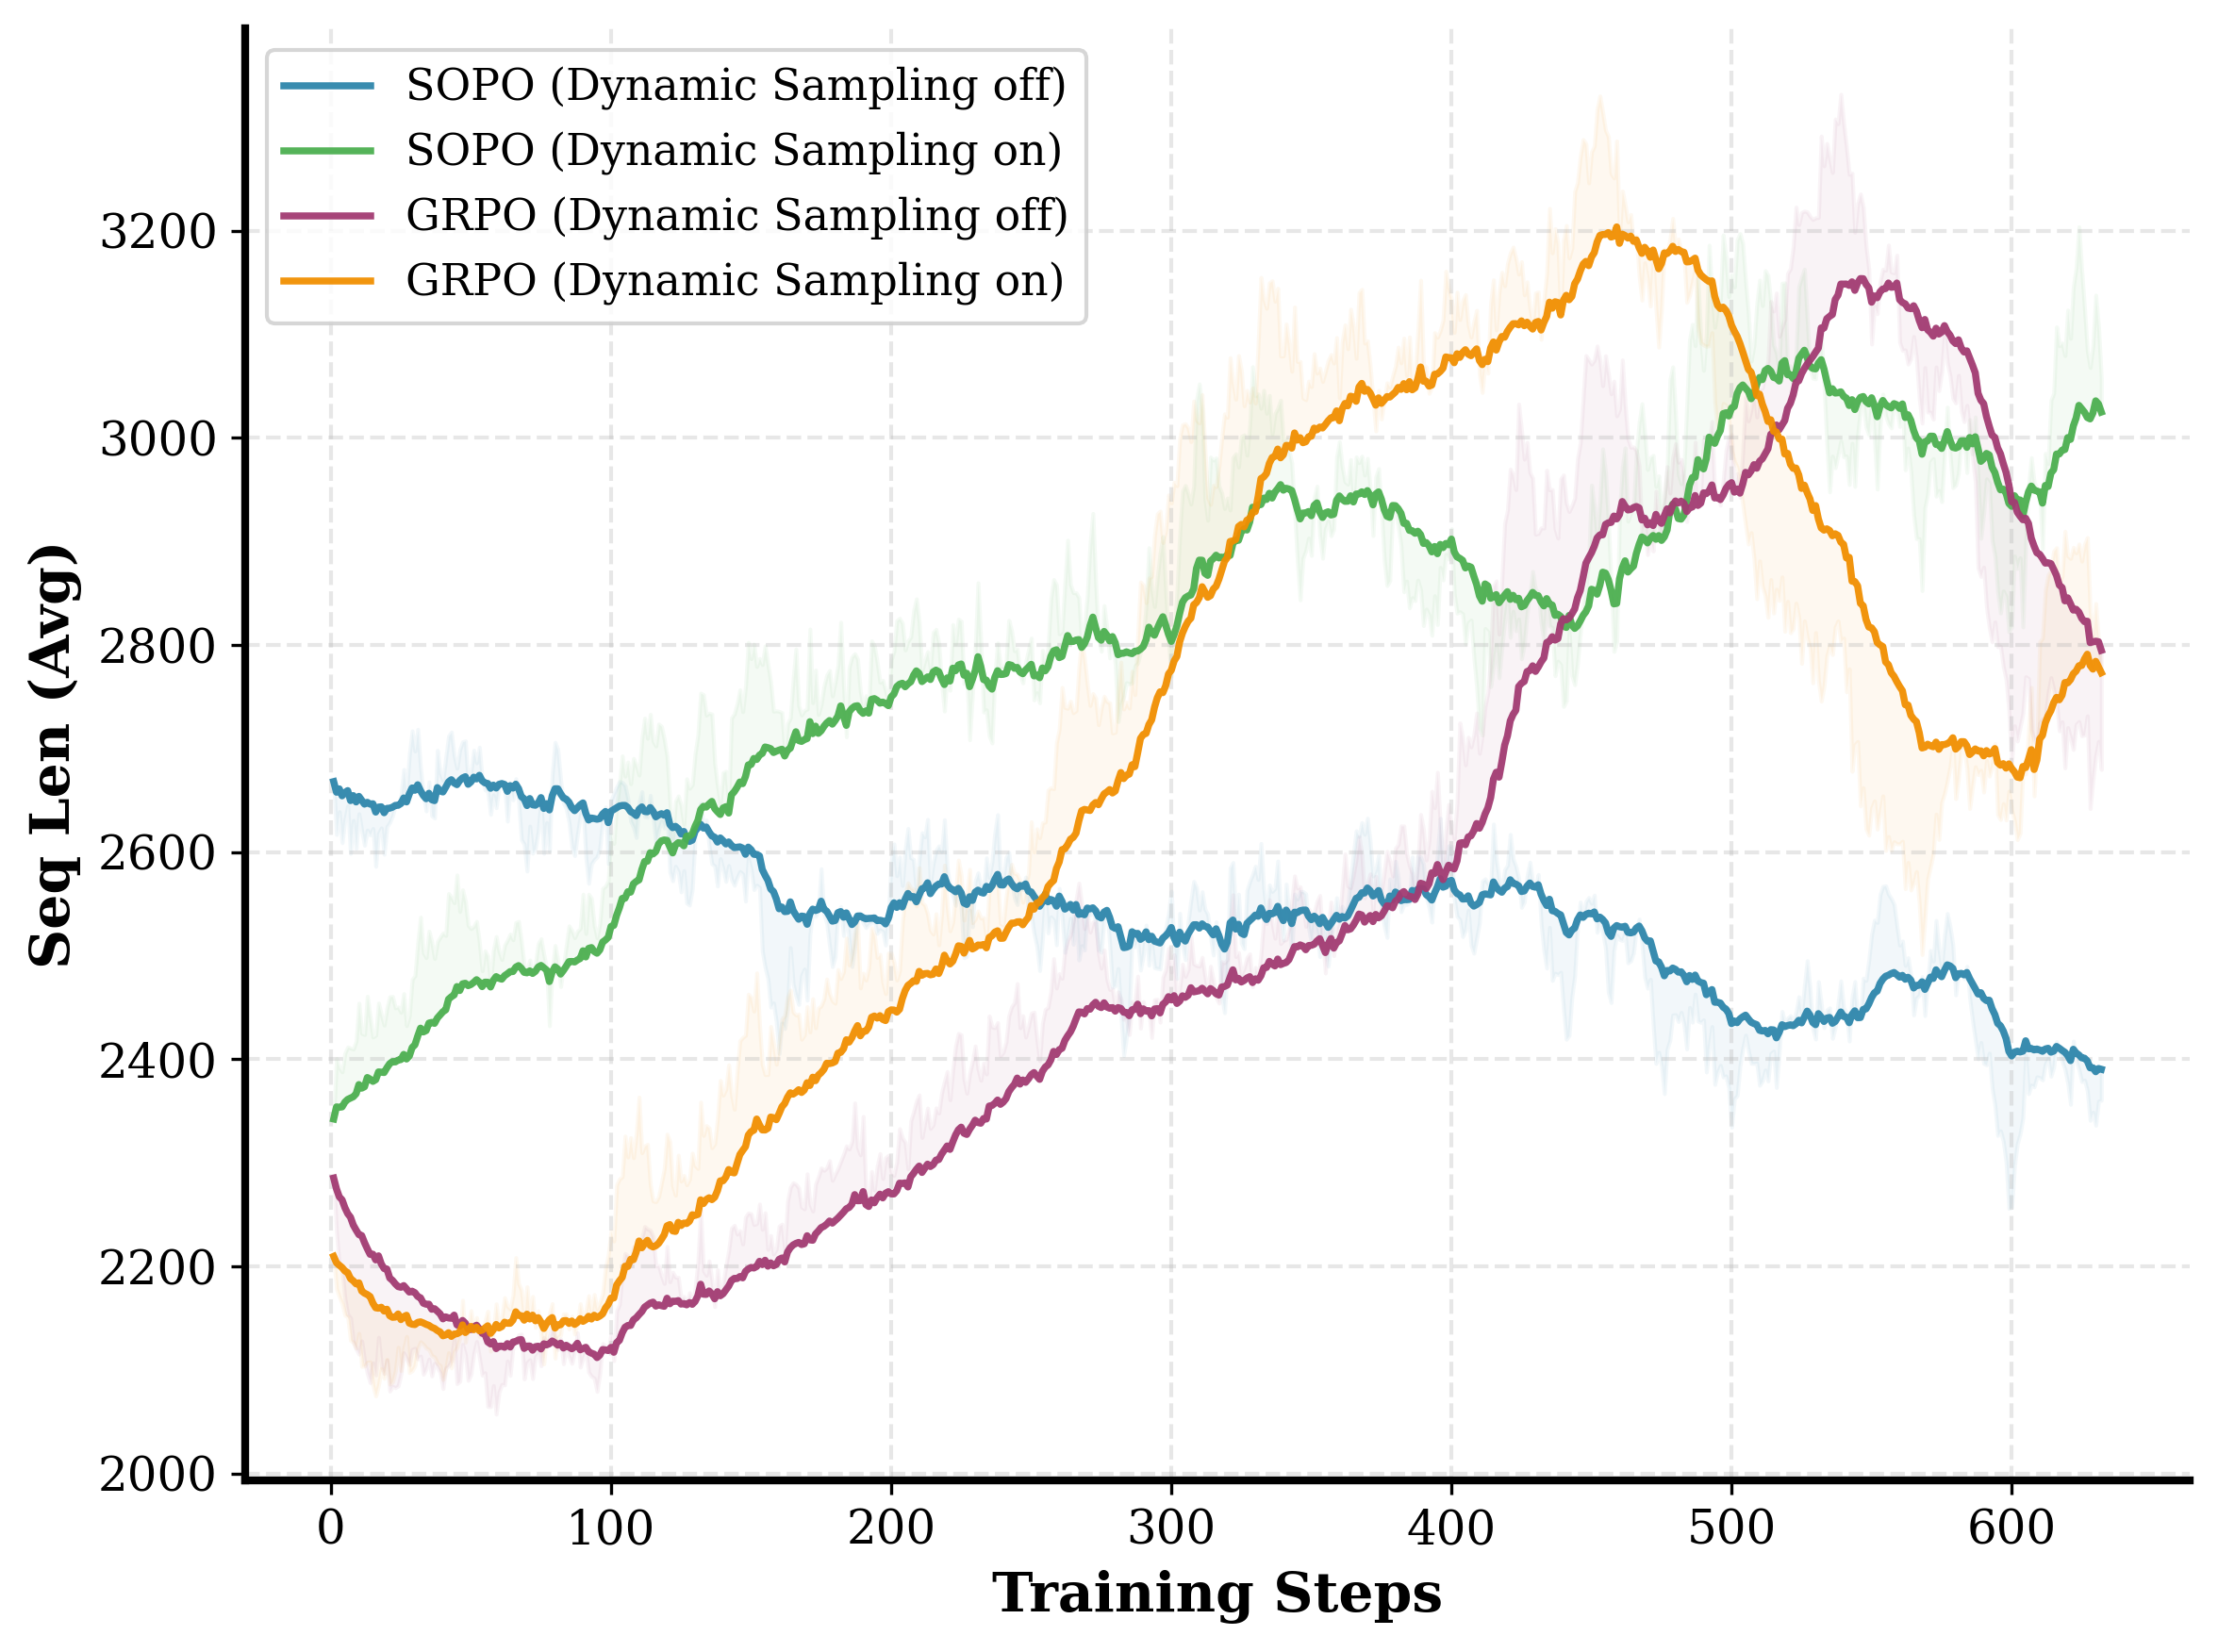

图2已保存至: /mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/seq_len_per_turn_4_methods.png


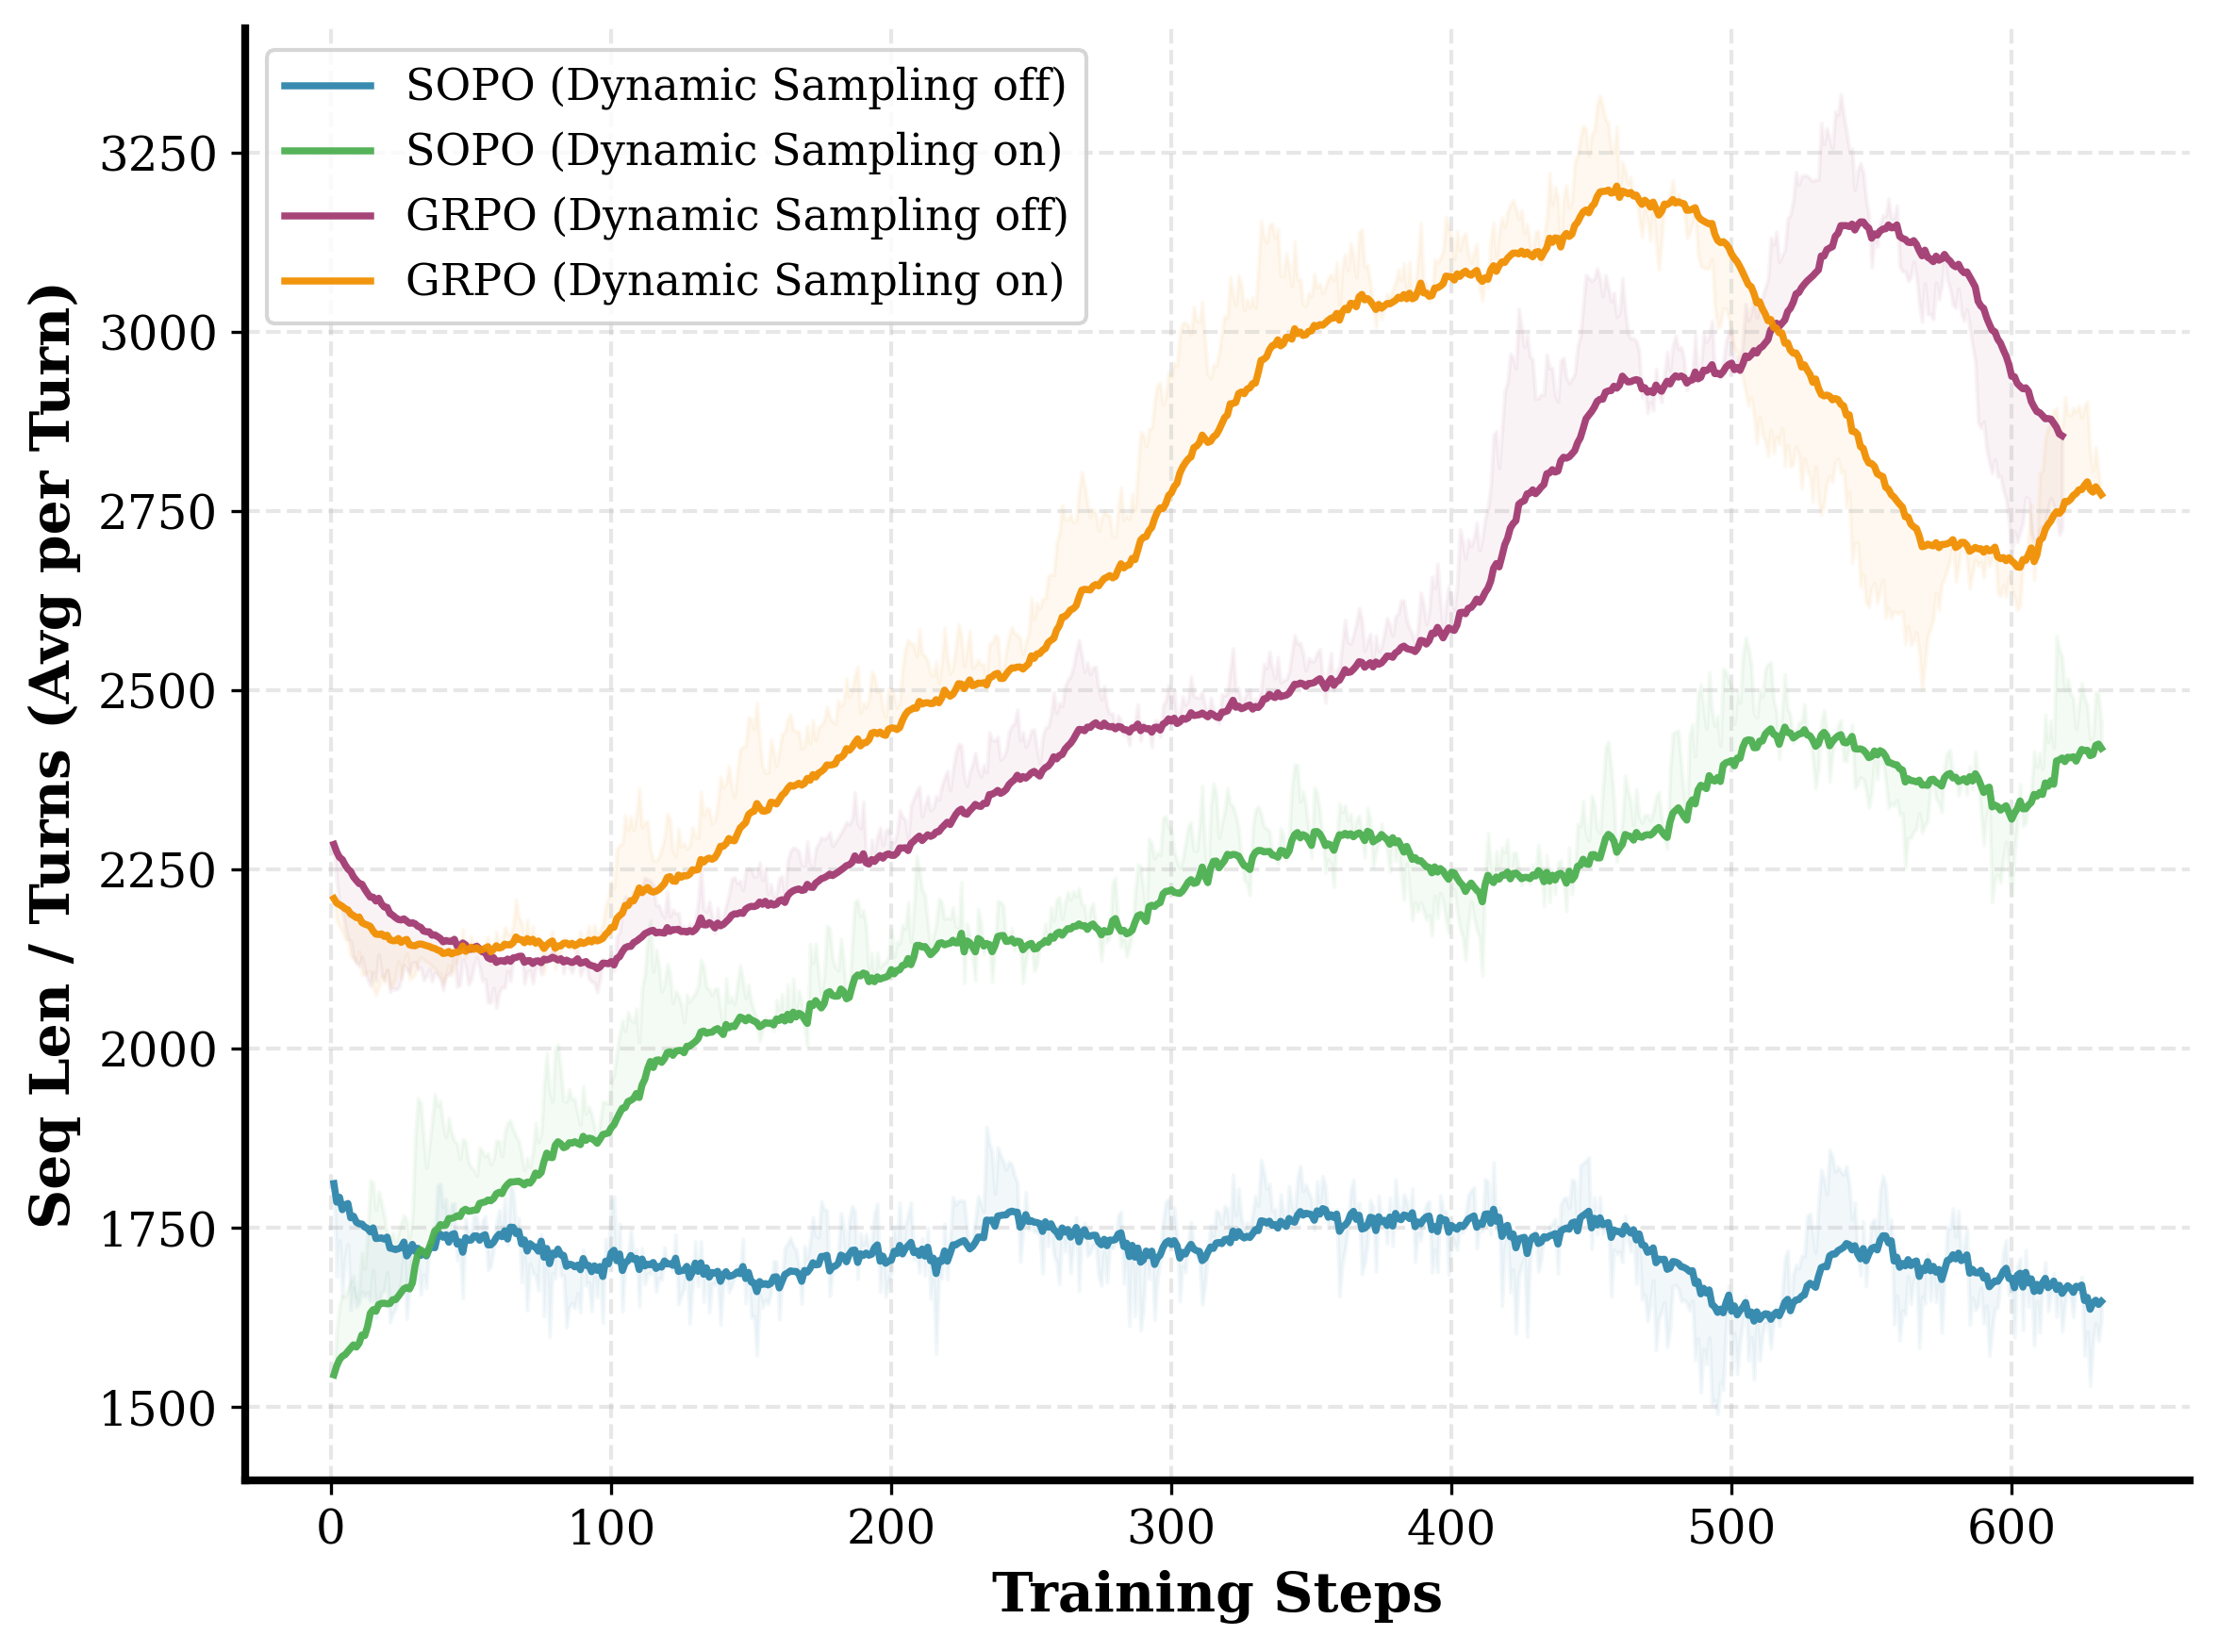

In [11]:
# Figure 1 & 2: length comparison under 4 methods
metric_seq_len = "ppo_actor/seq_len/avg"
metric_turns = "rollout/turns"

tb_sopo = tb_sopo_n8
tb_ori = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/tensorboard/havor/trial20251228_ragtruth_10k_ori_ds"

# 复用上一个cell的4个实验路径
steps_sopo_seq, values_sopo_seq = load_tensorboard_scalar(tb_sopo, metric_seq_len)
steps_sopo_ds_seq, values_sopo_ds_seq = load_tensorboard_scalar(tb_sopo_ds, metric_seq_len)
steps_ori_seq, values_ori_seq = load_tensorboard_scalar(tb_ori, metric_seq_len)
steps_ori_ds_seq, values_ori_ds_seq = load_tensorboard_scalar(tb_ori_ds, metric_seq_len)

steps_sopo_turns, values_sopo_turns = load_tensorboard_scalar(tb_sopo, metric_turns)
steps_sopo_ds_turns, values_sopo_ds_turns = load_tensorboard_scalar(tb_sopo_ds, metric_turns)
steps_ori_turns, values_ori_turns = load_tensorboard_scalar(tb_ori, metric_turns)
steps_ori_ds_turns, values_ori_ds_turns = load_tensorboard_scalar(tb_ori_ds, metric_turns)

series_seq = [
    ("SOPO (Dynamic Sampling off)", steps_sopo_seq, values_sopo_seq, "#2E86AB"),
    ("SOPO (Dynamic Sampling on)", steps_sopo_ds_seq, values_sopo_ds_seq, "#4CAF50"),
    ("GRPO (Dynamic Sampling off)", steps_ori_seq, values_ori_seq, "#A23B72"),
    ("GRPO (Dynamic Sampling on)", steps_ori_ds_seq, values_ori_ds_seq, "#F18F01"),
]

series_turns = {
    "SOPO (Dynamic Sampling off)": (steps_sopo_turns, values_sopo_turns),
    "SOPO (Dynamic Sampling on)": (steps_sopo_ds_turns, values_sopo_ds_turns),
    "GRPO (Dynamic Sampling off)": (steps_ori_turns, values_ori_turns),
    "GRPO (Dynamic Sampling on)": (steps_ori_ds_turns, values_ori_ds_turns),
}

max_points = 632
smoothing = 0.97
smoothing_fill = 0.85
line_width = 1.8
alpha_fill = 0.06

# 图1：ppo_actor/seq_len/avg
fig1, ax1 = plt.subplots(figsize=(8, 6))
for label, steps, values, color in series_seq:
    if steps is None or values is None or len(values) == 0:
        print(f"Warning: missing seq_len data for {label}")
        continue

    steps_plot = steps[:max_points]
    values_plot = values[:max_points]
    values_smooth = smooth(values_plot, weight=smoothing)
    values_smooth_fill = smooth(values_plot, weight=smoothing_fill)

    ax1.fill_between(
        steps_plot,
        values_smooth_fill,
        values_smooth,
        alpha=alpha_fill,
        color=color,
        label="_nolegend_",
        interpolate=True,
    )
    ax1.plot(
        steps_plot,
        values_smooth,
        label=label,
        linewidth=line_width,
        color=color,
        alpha=0.95,
    )

ax1.set_xlabel("Training Steps", fontsize=14, fontweight="bold")
ax1.set_ylabel("Seq Len (Avg)", fontsize=14, fontweight="bold")
ax1.legend(loc="upper left", fontsize=11, frameon=True, fancybox=True, shadow=False)
ax1.grid(True, alpha=0.3, linestyle="--", linewidth=1.0)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_linewidth(2)
ax1.spines["bottom"].set_linewidth(2)
plt.tight_layout()

output_path1 = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/seq_len_4_methods.png"
plt.savefig(output_path1, dpi=300, bbox_inches="tight")
print(f"图1已保存至: {output_path1}")
plt.show()

# 图2：ppo_actor/seq_len/avg 除以 rollout/turns
fig2, ax2 = plt.subplots(figsize=(8, 6))
for label, steps_seq, values_seq, color in series_seq:
    steps_turn, values_turn = series_turns[label]
    if (
        steps_seq is None
        or values_seq is None
        or steps_turn is None
        or values_turn is None
        or len(values_seq) == 0
        or len(values_turn) == 0
    ):
        print(f"Warning: missing seq_len/turns data for {label}")
        continue

    n = min(len(values_seq), len(values_turn), max_points)
    steps_plot = steps_seq[:n]
    seq_plot = values_seq[:n]
    turns_plot = values_turn[:n]

    ratio = np.divide(
        seq_plot,
        turns_plot,
        out=np.full_like(seq_plot, np.nan, dtype=float),
        where=turns_plot > 0,
    )
    valid = ~np.isnan(ratio)
    if valid.sum() == 0:
        print(f"Warning: turns are all non-positive for {label}")
        continue

    steps_valid = steps_plot[valid]
    ratio_valid = ratio[valid]

    ratio_smooth = smooth(ratio_valid, weight=smoothing)
    ratio_smooth_fill = smooth(ratio_valid, weight=smoothing_fill)

    ax2.fill_between(
        steps_valid,
        ratio_smooth_fill,
        ratio_smooth,
        alpha=alpha_fill,
        color=color,
        label="_nolegend_",
        interpolate=True,
    )
    ax2.plot(
        steps_valid,
        ratio_smooth,
        label=label,
        linewidth=line_width,
        color=color,
        alpha=0.95,
    )

ax2.set_xlabel("Training Steps", fontsize=14, fontweight="bold")
ax2.set_ylabel("Seq Len / Turns (Avg per Turn)", fontsize=14, fontweight="bold")
ax2.legend(loc="upper left", fontsize=11, frameon=True, fancybox=True, shadow=False)
ax2.grid(True, alpha=0.3, linestyle="--", linewidth=1.0)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_linewidth(2)
ax2.spines["bottom"].set_linewidth(2)
plt.tight_layout()

output_path2 = "/mnt/cfs-rd/dongjiawei/projects/rl/AReaL_20251111_040/plot/seq_len_per_turn_4_methods.png"
plt.savefig(output_path2, dpi=300, bbox_inches="tight")
print(f"图2已保存至: {output_path2}")
plt.show()